# 3 Wavelet Analysis of Real-Time Stock Market Data 

## 3.5 Daily Trading Data

### 3.5.1 Data Acquisition and Processing


In [8]:
import yfinance as yf
import pandas as pd

def load_stock_data(ticker="AAPL", period="20d", interval="1d"):
    """
    Load historical stock data from Yahoo Finance.
    
    Parameters:
    -----------
    ticker : str
        Stock symbol (default: AAPL)
    period : str  
        Time period for data retrieval (default: 20d)
        Valid options: 1d, 5d, 1mo, 3mo, 6mo, 1y, 2y, 5y, 10y, ytd, max
    interval : str
        Data interval (default: 1d for daily data)
        Valid options: 1m, 2m, 5m, 15m, 30m, 60m, 90m, 1h, 1d, 5d, 1wk, 1mo, 3mo
        
    Returns:
    --------
    pd.DataFrame
        DataFrame containing stock data with Date, Open, High, Low, Close, Volume
    """
    try:
        print(f"Fetching {period} of data for {ticker}...")
        stock_data = yf.download(ticker, period=period, interval=interval, 
                                progress=False, auto_adjust=True)
        stock_data.reset_index(inplace=True)
        
        # Flatten MultiIndex columns if present
        if isinstance(stock_data.columns, pd.MultiIndex):
            stock_data.columns = stock_data.columns.get_level_values(0)
        
        # Data validation
        if stock_data.empty:
            raise ValueError(f"No data retrieved for ticker {ticker}")
        
        # Check for required columns
        required_columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']
        missing_columns = [col for col in required_columns if col not in stock_data.columns]
        if missing_columns:
            raise ValueError(f"Missing required columns: {missing_columns}")
            
        print(f"Successfully loaded {len(stock_data)} days of data for {ticker}")
        print(f"\nDate range: {stock_data['Date'].min()} to {stock_data['Date'].max()}")
        print("\nStock Data Preview:")
        print(stock_data.head())
        
        # Display basic statistics - use .item() to extract scalar values
        avg_close = stock_data['Close'].mean()
        min_low = stock_data['Low'].min()
        max_high = stock_data['High'].max()
        avg_volume = stock_data['Volume'].mean()
        
        print("\nBasic Statistics:")
        print(f"Average Close Price: ${avg_close:.2f}")
        print(f"Price Range: ${min_low:.2f} - ${max_high:.2f}")
        print(f"Average Daily Volume: {avg_volume/1e6:.1f}M shares")
        
        return stock_data
        
    except Exception as e:
        print(f"Error loading stock data: {e}")
        return None

# Example usage
if __name__ == "__main__":   
    stock_data = load_stock_data()

Fetching 20d of data for AAPL...
Successfully loaded 20 days of data for AAPL

Date range: 2025-09-11 00:00:00 to 2025-10-08 00:00:00

Stock Data Preview:
Price       Date       Close        High         Low        Open    Volume
0     2025-09-11  230.029999  230.449997  226.649994  226.880005  50208600
1     2025-09-12  234.070007  234.509995  229.020004  229.220001  55824200
2     2025-09-15  236.699997  238.190002  235.029999  237.000000  42699500
3     2025-09-16  238.149994  241.220001  236.320007  237.179993  63421100
4     2025-09-17  238.990005  240.100006  237.729996  238.970001  46508000

Basic Statistics:
Average Close Price: $249.37
Price Range: $226.65 - $259.24
Average Daily Volume: 55.2M shares


### 3.5.2 Interactive Data Visualization

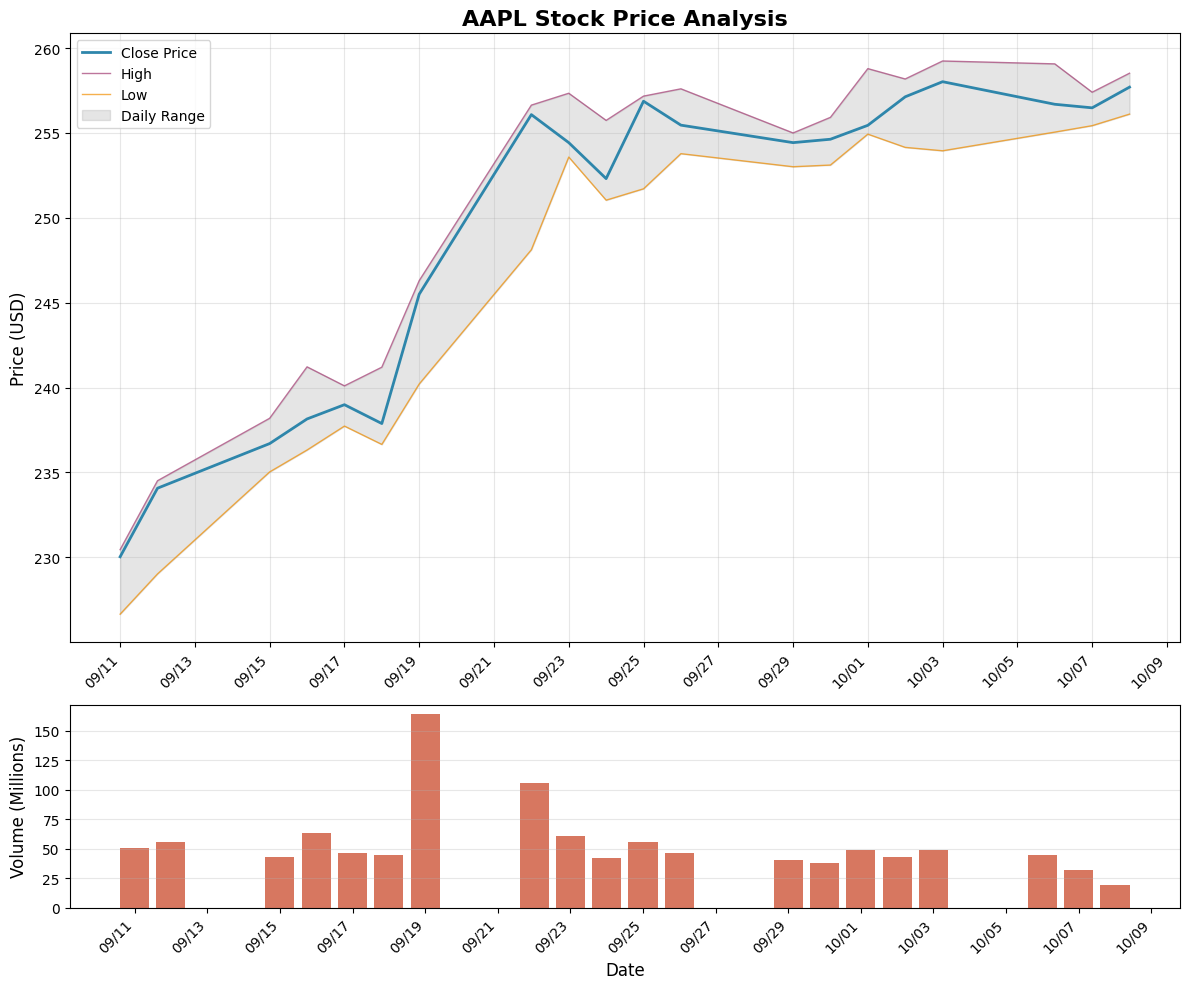


Key Visualization Statistics:
Price Range: $226.65 - $259.24
Average Volume: 54.5M shares
Price Volatility (std): $9.28
Average Daily Return: 0.61%
Return Volatility: 1.35%


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


def visualize_stock_data(stock_data, show_volume=True):
    """
    Create comprehensive visualization of stock data.
    
    Parameters:
    -----------
    stock_data : pd.DataFrame
        Stock data with Date, Open, High, Low, Close, Volume columns
    show_volume : bool
        Whether to include volume subplot (default: True)
    """
    # Flatten columns if MultiIndex
    if isinstance(stock_data.columns, pd.MultiIndex):
        stock_data = stock_data.copy()
        stock_data.columns = stock_data.columns.get_level_values(0)
    
    # Convert data to 1D arrays
    dates = stock_data['Date'].values
    close = stock_data['Close'].values
    high = stock_data['High'].values
    low = stock_data['Low'].values
    volume = stock_data['Volume'].values
    
    if show_volume:
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), 
                                      gridspec_kw={'height_ratios': [3, 1]})
    else:
        fig, ax1 = plt.subplots(1, 1, figsize=(12, 6))
    
    # Price plot
    ax1.plot(dates, close, label='Close Price', color='#2E86AB', linewidth=2)
    ax1.plot(dates, high, label='High', color='#A23B72', alpha=0.7, linewidth=1)
    ax1.plot(dates, low, label='Low', color='#F18F01', alpha=0.7, linewidth=1)
    
    ax1.fill_between(dates, low, high, alpha=0.2, color='gray', label='Daily Range')
    
    ax1.set_title('AAPL Stock Price Analysis', fontsize=16, fontweight='bold')
    ax1.set_ylabel('Price (USD)', fontsize=12)
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc='upper left')
    
    # Format x-axis dates
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
    ax1.xaxis.set_major_locator(mdates.DayLocator(interval=2))
    plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # Volume plot (if requested)
    if show_volume:
        ax2.bar(dates, volume/1e6, color='#C73E1D', alpha=0.7, width=0.8)
        ax2.set_ylabel('Volume (Millions)', fontsize=12)
        ax2.set_xlabel('Date', fontsize=12)
        ax2.grid(True, alpha=0.3, axis='y')
        ax2.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
        ax2.xaxis.set_major_locator(mdates.DayLocator(interval=2))
        plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.savefig('./output/aapl_stock_analysis.png', dpi=300)
    plt.show()
    
    # Print key statistics
    print(f"\nKey Visualization Statistics:")
    print(f"Price Range: ${low.min():.2f} - ${high.max():.2f}")
    print(f"Average Volume: {volume.mean()/1e6:.1f}M shares")
    print(f"Price Volatility (std): ${close.std():.2f}")
    
    # Calculate daily returns
    daily_returns = pd.Series(close).pct_change().dropna()
    print(f"Average Daily Return: {daily_returns.mean()*100:.2f}%")
    print(f"Return Volatility: {daily_returns.std()*100:.2f}%")


# Example usage
if __name__ == "__main__":
    #stock_data = load_stock_data()
    if stock_data is not None:
        visualize_stock_data(stock_data)

## 3.6 High-Performance Data Storage with DuckDB

### 3.6.1 Database Schema Design and Storage

In [7]:
import duckdb
from pathlib import Path

def save_to_duckdb(stock_data, table_name="stocks", db_path=":memory:"):
    """
    Save DataFrame to DuckDB with optimized schema and indexing.
    
    Parameters:
    -----------
    stock_data : pd.DataFrame
        Stock data to save
    table_name : str
        Name of the table to create
    db_path : str
        Database path (:memory: for in-memory, or path to .db file)
        
    Returns:
    --------
    duckdb.DuckDBPyConnection
        Database connection object
    """
    try:
        # Create connection
        con = duckdb.connect(db_path)
        
        # Check if 'Adj Close' column exists
        has_adj_close = 'Adj Close' in stock_data.columns
        
        # Register DataFrame as temporary view
        con.register('temp_stocks', stock_data)
        
        # Create table with proper data types and constraints
        # Build the query dynamically based on available columns
        if has_adj_close:
            adj_close_col = '"Adj Close"::DECIMAL(10,2) as Adj_Close,'
        else:
            adj_close_col = ''
        
        create_table_sql = f"""
        CREATE TABLE {table_name} AS 
        SELECT 
            Date::DATE as Date,
            Open::DECIMAL(10,2) as Open,
            High::DECIMAL(10,2) as High, 
            Low::DECIMAL(10,2) as Low,
            Close::DECIMAL(10,2) as Close,
            {adj_close_col}
            Volume::BIGINT as Volume
        FROM temp_stocks
        ORDER BY Date DESC
        """
        
        con.execute(create_table_sql)
        
        # Create index for better query performance
        con.execute(f"CREATE INDEX idx_{table_name}_date ON {table_name}(Date)")
        
        # Verify data insertion
        row_count = con.execute(f"SELECT COUNT(*) FROM {table_name}").fetchone()[0]
        
        print(f"✓ Successfully saved {row_count} rows to DuckDB table '{table_name}'")
        print(f"✓ Database location: {db_path}")
        
        # Display schema information
        schema_info = con.execute(f"DESCRIBE {table_name}").fetchdf()
        print(f"\nTable Schema:")
        print(schema_info.to_string(index=False))
        
        return con
        
    except Exception as e:
        print(f"Error saving to DuckDB: {e}")
        return None

def read_from_duckdb(con, table_name="stocks", limit=5, order_by="Date DESC"):
    """
    Query data from DuckDB with flexible filtering options.
    
    Parameters:
    -----------
    con : duckdb.DuckDBPyConnection
        Database connection
    table_name : str
        Table name to query
    limit : int
        Number of rows to return
    order_by : str
        ORDER BY clause
        
    Returns:
    --------
    pd.DataFrame
        Query results
    """
    try:
        # Check if Adj_Close column exists
        columns = con.execute(f"DESCRIBE {table_name}").fetchdf()['column_name'].tolist()
        has_adj_close = 'Adj_Close' in columns
        
        adj_close_select = 'Adj_Close,' if has_adj_close else ''
        
        query = f"""
        SELECT 
            Date,
            Open, High, Low, Close,
            {adj_close_select}
            Volume,
            ROUND((Close - LAG(Close) OVER (ORDER BY Date)) / 
                  LAG(Close) OVER (ORDER BY Date) * 100, 2) as Daily_Change_Pct
        FROM {table_name} 
        ORDER BY {order_by} 
        LIMIT {limit}
        """
        
        result = con.execute(query).fetchdf()
        
        print(f"\nQuery Results - Top {limit} rows:")
        print("=" * 80)
        print(result.to_string(index=False))
        
        return result
        
    except Exception as e:
        print(f"Error reading from DuckDB: {e}")
        return None

def perform_analytical_queries(con, table_name="stocks"):
    """
    Demonstrate DuckDB's analytical capabilities with complex queries.
    
    Parameters:
    -----------
    con : duckdb.DuckDBPyConnection
        Database connection
    table_name : str
        Table name to query
    """
    print("\n" + "="*60)
    print("Advanced Analytical Queries")
    print("="*60)
    
    # Query 1: Moving averages
    print("\n1. Moving Averages (5-day and 10-day):")
    ma_query = f"""
    SELECT 
        Date,
        Close,
        ROUND(AVG(Close) OVER (ORDER BY Date ROWS BETWEEN 4 PRECEDING AND CURRENT ROW), 2) as MA_5,
        ROUND(AVG(Close) OVER (ORDER BY Date ROWS BETWEEN 9 PRECEDING AND CURRENT ROW), 2) as MA_10
    FROM {table_name}
    ORDER BY Date DESC
    LIMIT 5
    """
    print(con.execute(ma_query).fetchdf().to_string(index=False))
    
    # Query 2: Daily volatility
    print("\n2. Daily Price Volatility:")
    volatility_query = f"""
    SELECT 
        Date,
        Close,
        ROUND((High - Low) / Close * 100, 2) as Intraday_Volatility_Pct
    FROM {table_name}
    ORDER BY Intraday_Volatility_Pct DESC
    LIMIT 5
    """
    print(con.execute(volatility_query).fetchdf().to_string(index=False))
    
    # Query 3: Summary statistics
    print("\n3. Overall Summary Statistics:")
    summary_query = f"""
    SELECT 
        COUNT(*) as Trading_Days,
        ROUND(MIN(Low), 2) as Min_Price,
        ROUND(MAX(High), 2) as Max_Price,
        ROUND(AVG(Close), 2) as Avg_Close,
        ROUND(STDDEV(Close), 2) as Price_StdDev,
        ROUND(SUM(Volume)/1e6, 1) as Total_Volume_Millions
    FROM {table_name}
    """
    print(con.execute(summary_query).fetchdf().to_string(index=False))

In [8]:
# In-memory (temporary)
#save_to_duckdb(stock_data, db_path=":memory:")  # Data lost after program ends

# Persistent file
#save_to_duckdb(stock_data, db_path="stock_data.db")  # Data saved to disk

# Another session can access it
save_to_duckdb(stock_data, db_path="./data/stocks.duckdb")  # With directory path

Error saving to DuckDB: Catalog Error: Table with name "stocks" already exists!


In [9]:
import duckdb
# Example usage
con = duckdb.connect("./data/stocks.duckdb")
stock_data = read_from_duckdb(con, limit=10)


Query Results - Top 10 rows:
      Date   Open   High    Low  Close    Volume  Daily_Change_Pct
2025-10-03 254.67 259.24 253.95 258.02  49107000              0.35
2025-10-02 256.58 258.18 254.15 257.13  42630200              0.66
2025-10-01 255.04 258.79 254.93 255.45  48713900              0.32
2025-09-30 254.86 255.92 253.11 254.63  37704300              0.08
2025-09-29 254.56 255.00 253.01 254.43  40127700             -0.40
2025-09-26 254.10 257.60 253.78 255.46  46076300             -0.55
2025-09-25 253.21 257.17 251.71 256.87  55202100              1.81
2025-09-24 255.22 255.74 251.04 252.31  42303700             -0.83
2025-09-23 255.88 257.34 253.58 254.43  60275200             -0.64
2025-09-22 248.30 256.64 248.12 256.08 105517400              4.31


In [8]:
perform_analytical_queries(con)


Advanced Analytical Queries

1. Moving Averages (5-day and 10-day):
      Date  Close   MA_5  MA_10
2025-10-03 258.02 255.93 255.48
2025-10-02 257.13 255.42 254.23
2025-10-01 255.45 255.37 252.30
2025-09-30 254.63 254.74 250.66
2025-09-29 254.43 254.70 249.01

2. Daily Price Volatility:
      Date  Close  Intraday_Volatility_Pct
2025-09-22 256.08                     3.33
2025-09-10 226.79                     2.85
2025-09-19 245.50                     2.48
2025-09-12 234.07                     2.35
2025-09-09 234.35                     2.31

3. Overall Summary Statistics:
 Trading_Days  Min_Price  Max_Price  Avg_Close  Price_StdDev  Total_Volume_Millions
           20     225.95     259.24     245.76         10.65                 1193.1


## 3.7 Wavelet Transform Analysis

### 3.7.2 Implementation

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from scipy import signal

def apply_wavelet_transform(stock_data, scales=None, wavelet='mexh', plot_scalogram=True):
    """
    Apply Continuous Wavelet Transform with comprehensive analysis.
    
    Parameters:
    -----------
    stock_data : pd.DataFrame
        Stock data containing Close prices
    scales : array-like
        Scales for CWT analysis (default: logarithmic scale 1-20)
    wavelet : str
        Wavelet type (default: 'mexh' - Mexican Hat)
        Other options: 'morl' (Morlet), 'gaus1'-'gaus8' (Gaussian derivatives)
    plot_scalogram : bool
        Whether to generate scalogram visualization
        
    Returns:
    --------
    tuple
        (coefficients, frequencies, scales_used)
    """
    # Default scales - logarithmic distribution for better frequency resolution
    if scales is None:
        scales = np.logspace(0, np.log10(20), 25)
    
    # Extract close prices and handle any missing values
    close_prices = stock_data['Close'].values
    close_prices = np.nan_to_num(close_prices)
    
    # Normalize prices for better wavelet analysis
    price_mean = np.mean(close_prices)
    price_std = np.std(close_prices)
    price_normalized = (close_prices - price_mean) / price_std
    
    # Apply Continuous Wavelet Transform
    coefficients, frequencies = pywt.cwt(price_normalized, scales, wavelet)
    
    # Print analysis summary
    print(f"\nWavelet Analysis Summary:")
    print(f"├─ Wavelet type: {wavelet}")
    print(f"├─ Number of scales: {len(scales)}")
    print(f"├─ Data points: {len(close_prices)}")
    print(f"├─ Coefficient matrix shape: {coefficients.shape}")
    print(f"├─ Frequency range: {frequencies.min():.3f} - {frequencies.max():.3f}")
    print(f"└─ Normalization: μ={price_mean:.2f}, σ={price_std:.2f}")
    
    if plot_scalogram:
        create_scalogram(coefficients, frequencies, scales, stock_data['Date'].values, 
                        close_prices, wavelet)
    
    # Perform additional analysis
    analyze_wavelet_features(coefficients, scales, stock_data)
    
    return coefficients, frequencies, scales

def create_scalogram(coefficients, frequencies, scales, dates, prices, wavelet_name):
    """Create comprehensive scalogram visualization."""
    
    import os
    os.makedirs('./output', exist_ok=True)
    
    fig = plt.figure(figsize=(15, 10), constrained_layout=True)
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 2, 1], width_ratios=[4, 1])
    
    # Original signal
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.plot(range(len(prices)), prices, 'b-', linewidth=2)
    ax1.set_title(f'Original AAPL Close Prices', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Price (USD)')
    ax1.grid(True, alpha=0.3)
    ax1.text(0.02, 0.98, f'μ=${np.mean(prices):.2f}, σ=${np.std(prices):.2f}', 
             transform=ax1.transAxes, fontsize=10, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # Scalogram
    ax2 = fig.add_subplot(gs[1, 0])
    coeffs_abs = np.abs(coefficients)
    im = ax2.imshow(coeffs_abs, extent=[0, len(prices), scales.min(), scales.max()], 
                    cmap='coolwarm', aspect='auto', origin='lower')
    ax2.set_title(f'CWT Scalogram ({wavelet_name} wavelet)', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Time (Days)')
    ax2.set_ylabel('Scale')
    ax2.set_yscale('log')
    cbar = fig.colorbar(im, ax=ax2)
    cbar.set_label('|Coefficient|', rotation=270, labelpad=20)
    
    # Scale-averaged power
    ax4 = fig.add_subplot(gs[2, 0])
    power = np.mean(coeffs_abs**2, axis=0)
    ax4.plot(power, 'r-', linewidth=2)
    ax4.fill_between(range(len(power)), power, alpha=0.3, color='red')
    ax4.set_title('Scale-Averaged Wavelet Power', fontsize=12, fontweight='bold')
    ax4.set_xlabel('Time (Days)')
    ax4.set_ylabel('Power')
    ax4.grid(True, alpha=0.3)
    
    if len(prices) > 50:
        plt.savefig('./output/aapl_wavelet_scalogram.png', dpi=300)
    
    plt.show()

def analyze_wavelet_features(coefficients, scales, stock_data):
    """Extract and analyze key features from wavelet coefficients."""
    
    print(f"\nWavelet Feature Analysis:")
    print("=" * 60)
    
    # Calculate energy at different scales
    energy_by_scale = np.sum(np.abs(coefficients)**2, axis=1)
    dominant_scale_idx = np.argmax(energy_by_scale)
    
    print(f"\nScale Energy Distribution:")
    print(f"├─ Dominant scale index: {dominant_scale_idx}")
    print(f"├─ Dominant scale value: {scales[dominant_scale_idx]:.2f}")
    print(f"└─ Dominant scale energy: {energy_by_scale[dominant_scale_idx]:.2f}")
    
    # Find periods of high volatility
    total_power = np.sum(np.abs(coefficients)**2, axis=0)
    volatility_threshold = np.mean(total_power) + 2 * np.std(total_power)
    high_volatility_periods = np.where(total_power > volatility_threshold)[0]
    
    print(f"\nVolatility Analysis:")
    print(f"├─ Mean power: {np.mean(total_power):.2f}")
    print(f"├─ Power std dev: {np.std(total_power):.2f}")
    print(f"└─ Volatility threshold: {volatility_threshold:.2f}")
    
    if len(high_volatility_periods) > 0:
        print(f"\nHigh Volatility Periods:")
        print(f"└─ Detected at days: {high_volatility_periods.tolist()}")
        
        # Get corresponding dates and prices
        dates = stock_data['Date'].values
        prices = stock_data['Close'].values
        
        print(f"\nVolatility Period Details:")
        for idx in high_volatility_periods[:5]:  # Show first 5
            if idx < len(dates):
                print(f"  Day {idx}: {dates[idx]}, Price: ${prices[idx]:.2f}, "
                      f"Power: {total_power[idx]:.2f}")
    else:
        print("\n└─ No significant volatility spikes detected")
    
    # Scale-wise statistics
    print(f"\nScale-wise Energy Distribution (5 representative scales):")
    print("-" * 60)
    step = max(1, len(scales)//5)
    for i in range(0, len(scales), step):
        pct_energy = (energy_by_scale[i] / np.sum(energy_by_scale)) * 100
        print(f"Scale {scales[i]:5.2f}: Energy = {energy_by_scale[i]:8.2f} ({pct_energy:5.2f}%)")
    
    # Frequency band analysis
    print(f"\nFrequency Band Analysis:")
    low_freq_energy = np.sum(energy_by_scale[len(scales)//2:])  # Low frequency (large scales)
    high_freq_energy = np.sum(energy_by_scale[:len(scales)//2])  # High frequency (small scales)
    
    print(f"├─ High frequency energy (short-term): {high_freq_energy:.2f}")
    print(f"├─ Low frequency energy (long-term): {low_freq_energy:.2f}")
    print(f"└─ Ratio (high/low): {high_freq_energy/low_freq_energy:.2f}")


Wavelet Analysis Summary:
├─ Wavelet type: mexh
├─ Number of scales: 25
├─ Data points: 10
├─ Coefficient matrix shape: (25, 10)
├─ Frequency range: 0.012 - 0.250
└─ Normalization: μ=255.48, σ=1.56


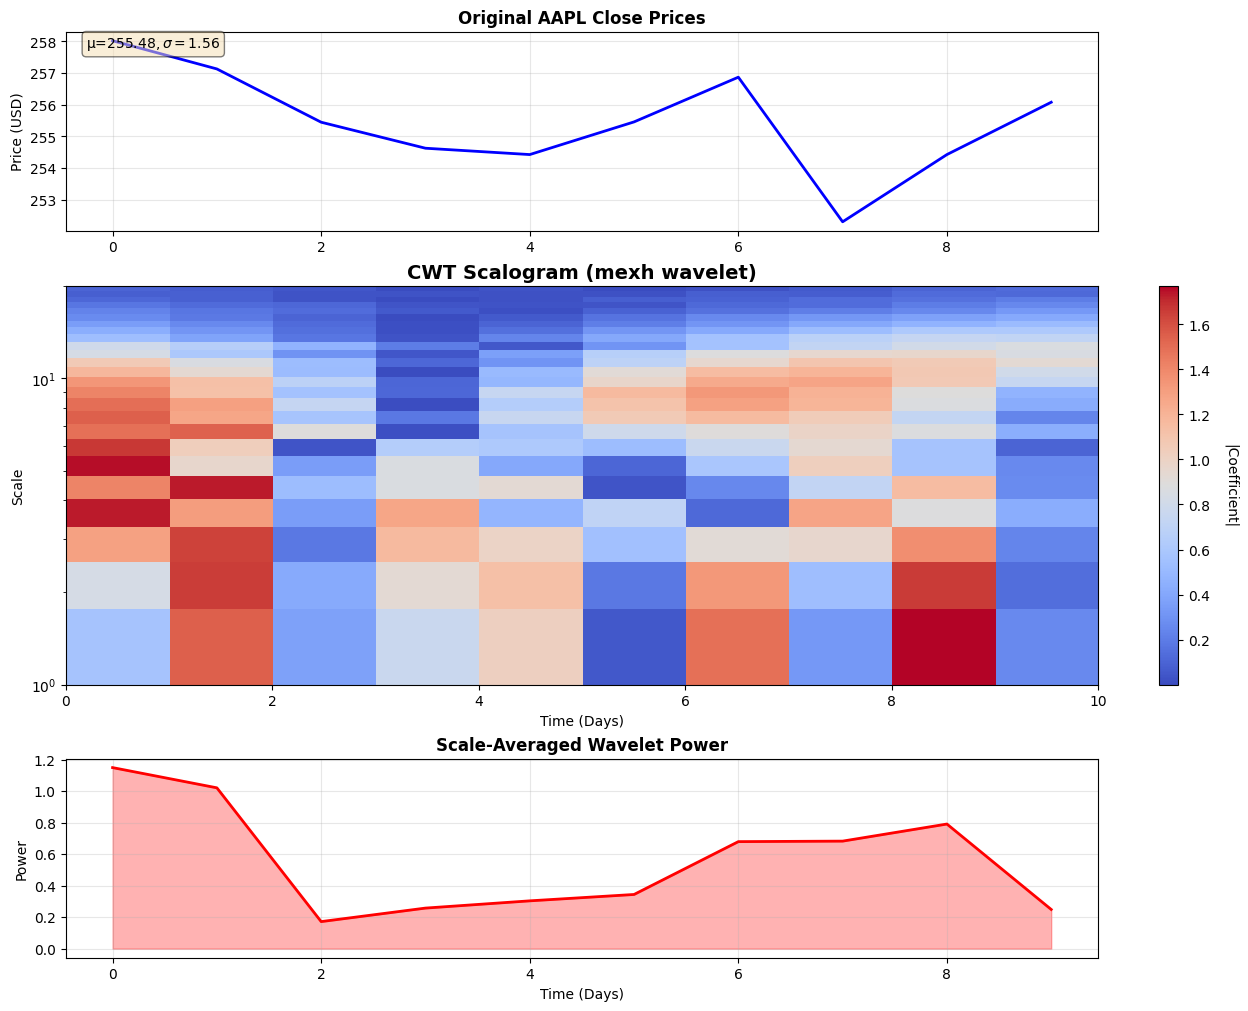


Wavelet Feature Analysis:

Scale Energy Distribution:
├─ Dominant scale index: 2
├─ Dominant scale value: 1.28
└─ Dominant scale energy: 10.72

Volatility Analysis:
├─ Mean power: 14.14
├─ Power std dev: 8.28
└─ Volatility threshold: 30.69

└─ No significant volatility spikes detected

Scale-wise Energy Distribution (5 representative scales):
------------------------------------------------------------
Scale  1.00: Energy =     9.98 ( 7.06%)
Scale  1.87: Energy =     6.81 ( 4.82%)
Scale  3.48: Energy =     9.73 ( 6.88%)
Scale  6.50: Energy =     3.66 ( 2.59%)
Scale 12.14: Energy =     0.35 ( 0.25%)

Frequency Band Analysis:
├─ High frequency energy (short-term): 111.10
├─ Low frequency energy (long-term): 30.29
└─ Ratio (high/low): 3.67


In [13]:
# Example usage
if __name__ == "__main__":
    #stock_data = load_stock_data()
    if stock_data is not None:
        apply_wavelet_transform(stock_data)

## 3.8 Complete Integration and Execution Pipeline


Example 1: Single Stock Analysis
🚀 Starting Stock Analysis Pipeline
Target: AAPL
Period: 20d
Database: :memory:
Timestamp: 2025-10-05 15:37:15

📊 Step 1: Loading Stock Data...
Fetching 20d of data for AAPL...
Successfully loaded 20 days of data for AAPL

Date range: 2025-09-08 00:00:00 to 2025-10-03 00:00:00

Stock Data Preview:
Price       Date       Close        High         Low        Open    Volume
0     2025-09-08  237.880005  240.149994  236.339996  239.300003  48999500
1     2025-09-09  234.350006  238.779999  233.360001  237.000000  66313900
2     2025-09-10  226.789993  232.419998  225.949997  232.190002  83440800
3     2025-09-11  230.029999  230.449997  226.649994  226.880005  50208600
4     2025-09-12  234.070007  234.509995  229.020004  229.220001  55824200

Basic Statistics:
Average Close Price: $245.76
Price Range: $225.95 - $259.24
Average Daily Volume: 59.7M shares
   ⏱️  Completed in 0.13s

📈 Step 2: Creating Visualizations...


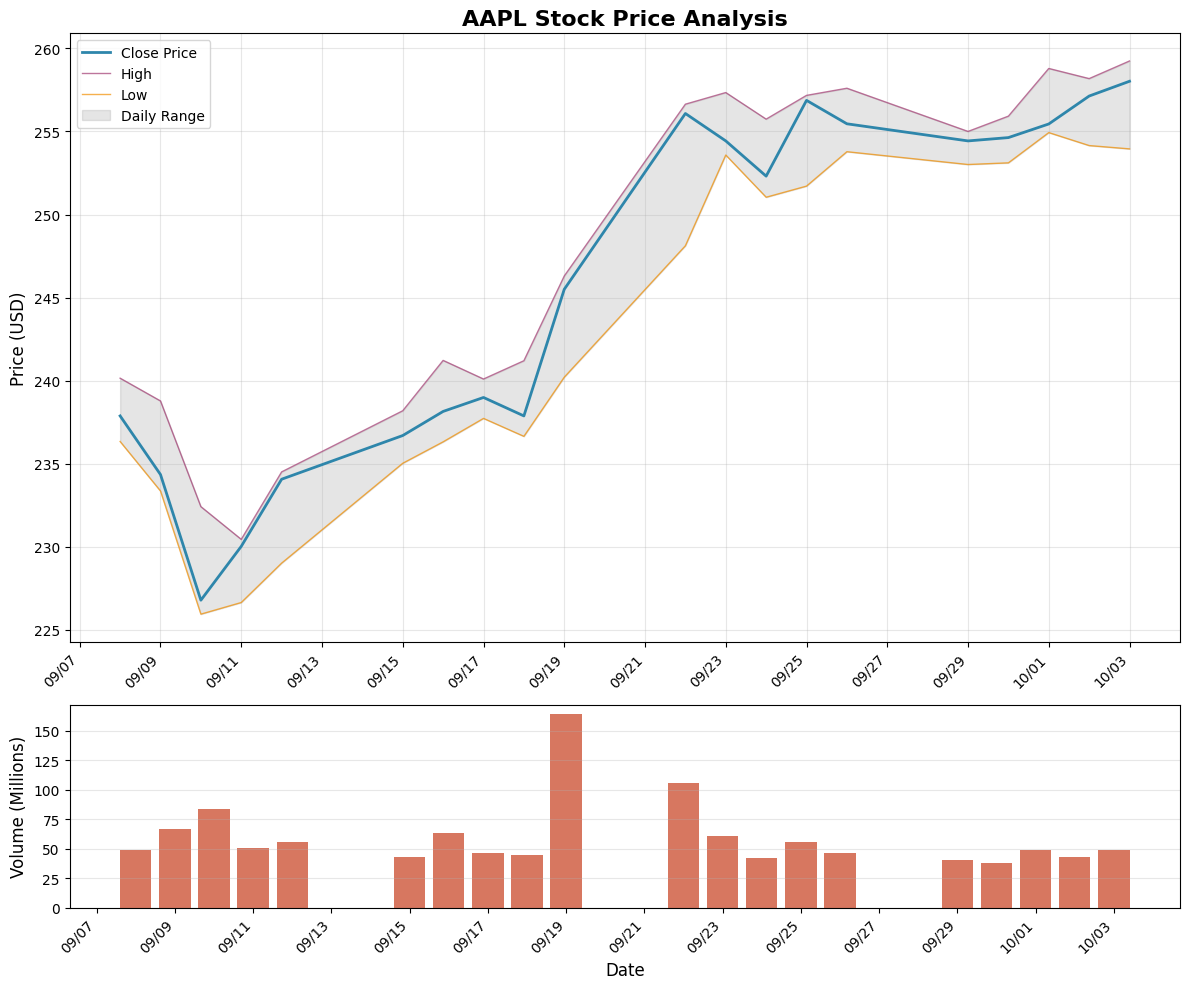


Key Visualization Statistics:
Price Range: $225.95 - $259.24
Average Volume: 59.7M shares
Price Volatility (std): $10.38
Average Daily Return: 0.44%
Return Volatility: 1.67%
   ⏱️  Completed in 0.68s

💾 Step 3: Saving to DuckDB...
✓ Successfully saved 20 rows to DuckDB table 'aapl_stocks'
✓ Database location: :memory:

Table Schema:
column_name   column_type null  key default extra
       Date          DATE  YES None    None  None
       Open DECIMAL(10,2)  YES None    None  None
       High DECIMAL(10,2)  YES None    None  None
        Low DECIMAL(10,2)  YES None    None  None
      Close DECIMAL(10,2)  YES None    None  None
     Volume        BIGINT  YES None    None  None
   ⏱️  Completed in 0.08s

🔍 Step 4: Verifying Data Storage...

Query Results - Top 10 rows:
      Date   Open   High    Low  Close    Volume  Daily_Change_Pct
2025-10-03 254.67 259.24 253.95 258.02  49107000              0.35
2025-10-02 256.58 258.18 254.15 257.13  42630200              0.66
2025-10-01 255.04 25

C:\Users\shouk\AppData\Local\Temp\ipykernel_25920\4224134104.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


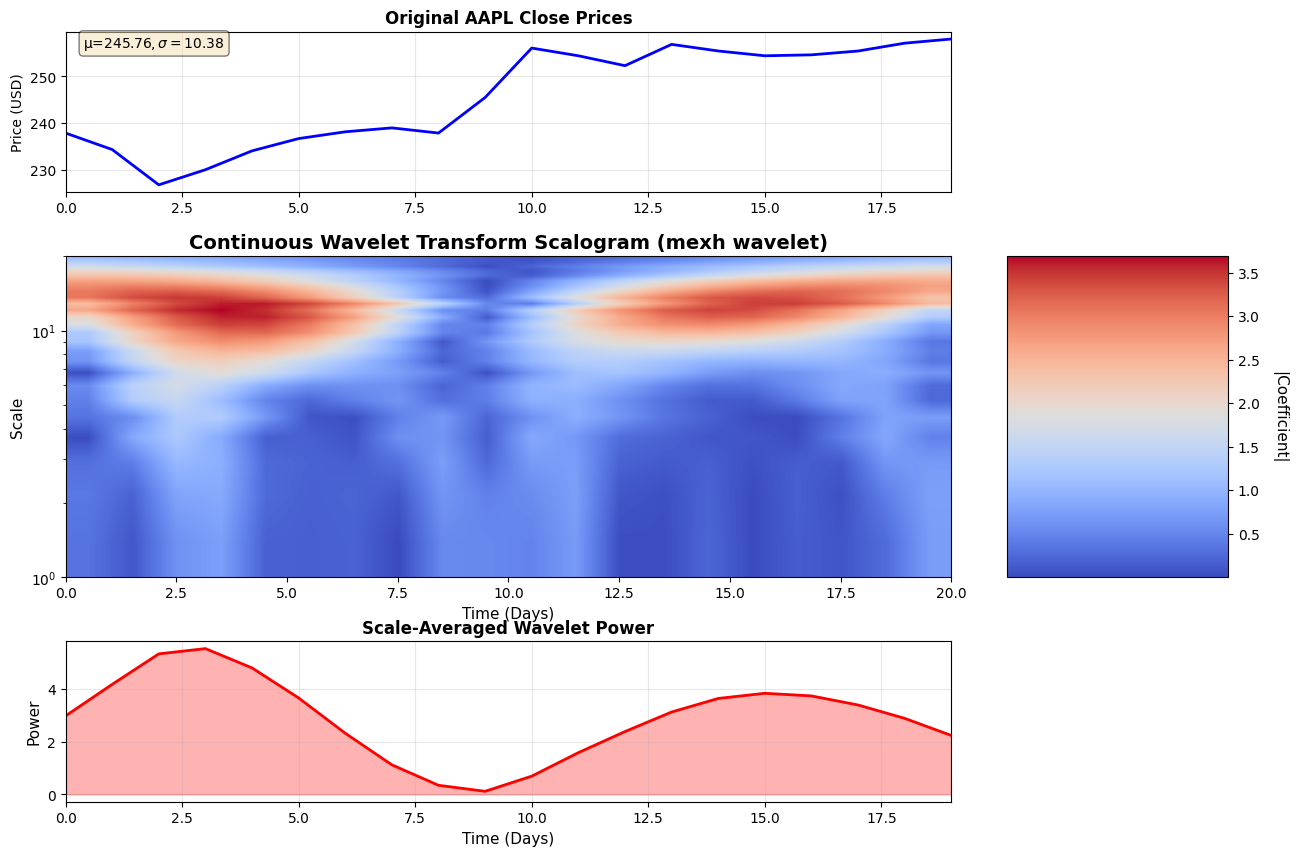


Wavelet Feature Analysis:

Scale Energy Distribution:
├─ Dominant scale index: 15
├─ Dominant scale value: 6.50
└─ Dominant scale energy: 153.02

Volatility Analysis:
├─ Mean power: 72.39
├─ Power std dev: 37.97
└─ Volatility threshold: 148.33

└─ No significant volatility spikes detected

Scale-wise Energy Distribution (5 representative scales):
------------------------------------------------------------
Scale  1.00: Energy =     3.17 ( 0.22%)
Scale  1.87: Energy =    10.52 ( 0.73%)
Scale  3.48: Energy =    63.06 ( 4.36%)
Scale  6.50: Energy =   153.02 (10.57%)
Scale 12.14: Energy =    58.63 ( 4.05%)

Frequency Band Analysis:
├─ High frequency energy (short-term): 296.11
├─ Low frequency energy (long-term): 1151.65
└─ Ratio (high/low): 0.26
   ⏱️  Completed in 0.44s

✅ Pipeline completed successfully!
Total execution time: 1.34 seconds
Data points processed: 20
Wavelet coefficients generated: 500
Memory usage (approx): 3.9 KB

🔒 Closing in-memory database connection...

🔍 Anomaly De

In [11]:
import time
from datetime import datetime

def main(ticker="AAPL", period="20d", save_plots=False, db_path=":memory:"):
    """
    Execute complete stock analysis pipeline with error handling and timing.
    
    Parameters:
    -----------
    ticker : str
        Stock symbol to analyze
    period : str
        Time period for analysis
    save_plots : bool
        Whether to save generated plots to disk
    db_path : str
        Database path (:memory: for in-memory, or filepath for persistent storage)
        
    Returns:
    --------
    dict
        Dictionary containing all pipeline results and metadata
    """
    start_time = time.time()
    
    print("🚀 Starting Stock Analysis Pipeline")
    print("=" * 60)
    print(f"Target: {ticker}")
    print(f"Period: {period}")
    print(f"Database: {db_path}")
    print(f"Timestamp: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    print("=" * 60)
    
    results = {}
    
    try:
        # Step 1: Data Loading
        print("\n📊 Step 1: Loading Stock Data...")
        step_start = time.time()
        stock_data = load_stock_data(ticker, period)
        if stock_data is None or stock_data.empty:
            raise ValueError("Failed to load stock data")
        results['stock_data'] = stock_data
        print(f"   ⏱️  Completed in {time.time() - step_start:.2f}s")
        
        # Step 2: Visualization  
        print("\n📈 Step 2: Creating Visualizations...")
        step_start = time.time()
        visualize_stock_data(stock_data)
        if save_plots:
            plt.savefig(f'{ticker}_price_volume.png', dpi=300, bbox_inches='tight')
            print(f"   💾 Saved plot: {ticker}_price_volume.png")
        print(f"   ⏱️  Completed in {time.time() - step_start:.2f}s")
        
        # Step 3: Database Storage
        print("\n💾 Step 3: Saving to DuckDB...")
        step_start = time.time()
        con = save_to_duckdb(stock_data, table_name=f"{ticker.lower()}_stocks", db_path=db_path)
        if con is None:
            raise ValueError("Failed to save data to DuckDB")
        results['database_connection'] = con
        print(f"   ⏱️  Completed in {time.time() - step_start:.2f}s")
        
        # Step 4: Data Verification
        print("\n🔍 Step 4: Verifying Data Storage...")
        step_start = time.time()
        verification_data = read_from_duckdb(con, table_name=f"{ticker.lower()}_stocks", limit=10)
        results['verification_data'] = verification_data
        
        # Perform analytical queries
        perform_analytical_queries(con, table_name=f"{ticker.lower()}_stocks")
        print(f"   ⏱️  Completed in {time.time() - step_start:.2f}s")
        
        # Step 5: Wavelet Analysis
        print("\n🌊 Step 5: Applying Wavelet Transform...")
        step_start = time.time()
        coefficients, frequencies, scales = apply_wavelet_transform(stock_data, plot_scalogram=True)
        if save_plots:
            plt.savefig(f'{ticker}_wavelet_scalogram.png', dpi=300, bbox_inches='tight')
            print(f"   💾 Saved plot: {ticker}_wavelet_scalogram.png")
        
        results['wavelet_coefficients'] = coefficients
        results['wavelet_frequencies'] = frequencies
        results['wavelet_scales'] = scales
        print(f"   ⏱️  Completed in {time.time() - step_start:.2f}s")
        
        # Performance summary
        end_time = time.time()
        execution_time = end_time - start_time
        results['execution_time'] = execution_time
        results['timestamp'] = datetime.now()
        
        print("\n" + "=" * 60)
        print("✅ Pipeline completed successfully!")
        print("=" * 60)
        print(f"Total execution time: {execution_time:.2f} seconds")
        print(f"Data points processed: {len(stock_data)}")
        print(f"Wavelet coefficients generated: {coefficients.size:,}")
        print(f"Memory usage (approx): {coefficients.nbytes / 1024:.1f} KB")
        print("=" * 60)
        
        return results
        
    except Exception as e:
        print(f"\n❌ Pipeline failed: {e}")
        import traceback
        traceback.print_exc()
        return None
    
    finally:
        # Cleanup if needed
        if 'database_connection' in results and db_path == ":memory:":
            print("\n🔒 Closing in-memory database connection...")

# Utility function for different analysis modes
def run_comparative_analysis(tickers=["AAPL", "MSFT", "GOOGL"], period="30d", db_path=":memory:"):
    """
    Run analysis on multiple stocks for comparison.
    
    Parameters:
    -----------
    tickers : list
        List of stock symbols to analyze
    period : str
        Time period for analysis
    db_path : str
        Database path for storing results
        
    Returns:
    --------
    dict
        Dictionary mapping tickers to their analysis results
    """
    results = {}
    
    print("\n" + "="*70)
    print("🔬 COMPARATIVE STOCK ANALYSIS")
    print("="*70)
    print(f"Analyzing {len(tickers)} stocks: {', '.join(tickers)}")
    print(f"Period: {period}")
    print("="*70)
    
    for i, ticker in enumerate(tickers, 1):
        print(f"\n{'='*20} [{i}/{len(tickers)}] Analyzing {ticker} {'='*20}")
        result = main(ticker, period, db_path=db_path)
        if result:
            results[ticker] = result
            print(f"✓ {ticker} analysis complete")
        else:
            print(f"✗ {ticker} analysis failed")
        
        # Rate limiting for API calls
        if i < len(tickers):
            print("\n⏳ Pausing 2 seconds to respect API rate limits...")
            time.sleep(2)
    
    # Generate comparative summary
    print("\n" + "="*70)
    print("📊 COMPARATIVE SUMMARY")
    print("="*70)
    
    for ticker, result in results.items():
        if result and 'stock_data' in result:
            data = result['stock_data']
            print(f"\n{ticker}:")
            print(f"  ├─ Days analyzed: {len(data)}")
            print(f"  ├─ Price range: ${data['Low'].min():.2f} - ${data['High'].max():.2f}")
            print(f"  ├─ Avg volume: {data['Volume'].mean()/1e6:.1f}M shares")
            print(f"  └─ Execution time: {result['execution_time']:.2f}s")
    
    return results

# Advanced analysis functions
def detect_anomalies(stock_data, wavelet_coefficients, threshold=3.0):
    """
    Detect anomalies in stock prices using wavelet coefficients.
    
    Parameters:
    -----------
    stock_data : pd.DataFrame
        Stock data with Date and Close columns
    wavelet_coefficients : np.ndarray
        Wavelet coefficient matrix from CWT
    threshold : float
        Number of standard deviations for anomaly detection
        
    Returns:
    --------
    list
        List of tuples (date, price, anomaly_score)
    """
    # Calculate total wavelet power across scales
    total_power = np.sum(np.abs(wavelet_coefficients)**2, axis=0)
    
    # Standardize power
    power_mean = np.mean(total_power)
    power_std = np.std(total_power)
    standardized_power = (total_power - power_mean) / power_std
    
    # Find anomalies
    anomaly_indices = np.where(np.abs(standardized_power) > threshold)[0]
    
    anomalies = []
    dates = stock_data['Date'].values
    prices = stock_data['Close'].values
    
    for idx in anomaly_indices:
        if idx < len(dates):
            anomalies.append((dates[idx], prices[idx], standardized_power[idx]))
    
    print(f"\n🔍 Anomaly Detection Results:")
    print(f"Threshold: {threshold} standard deviations")
    print(f"Anomalies detected: {len(anomalies)}")
    
    if anomalies:
        print("\nDetected Anomalies:")
        for date, price, score in sorted(anomalies, key=lambda x: abs(x[2]), reverse=True):
            print(f"  {date}: ${price:.2f} (score: {score:.2f})")
    
    return anomalies

def calculate_risk_metrics(stock_data):
    """
    Calculate financial risk metrics.
    
    Parameters:
    -----------
    stock_data : pd.DataFrame
        Stock data with Close column
        
    Returns:
    --------
    dict
        Dictionary containing various risk metrics
    """
    prices = stock_data['Close'].values
    returns = np.diff(prices) / prices[:-1]
    
    metrics = {
        'volatility_daily': np.std(returns),
        'volatility_annualized': np.std(returns) * np.sqrt(252),
        'sharpe_ratio': (np.mean(returns) / np.std(returns)) * np.sqrt(252) if np.std(returns) > 0 else 0,
        'max_drawdown': np.min(prices / np.maximum.accumulate(prices) - 1),
        'value_at_risk_95': np.percentile(returns, 5),
        'value_at_risk_99': np.percentile(returns, 1),
    }
    
    print("\n📉 Risk Metrics:")
    print("=" * 50)
    print(f"Daily Volatility: {metrics['volatility_daily']*100:.2f}%")
    print(f"Annualized Volatility: {metrics['volatility_annualized']*100:.2f}%")
    print(f"Sharpe Ratio: {metrics['sharpe_ratio']:.2f}")
    print(f"Maximum Drawdown: {metrics['max_drawdown']*100:.2f}%")
    print(f"VaR (95%): {metrics['value_at_risk_95']*100:.2f}%")
    print(f"VaR (99%): {metrics['value_at_risk_99']*100:.2f}%")
    
    return metrics

if __name__ == "__main__":
    # Example 1: Single stock analysis
    print("Example 1: Single Stock Analysis")
    result = main("AAPL", "20d", save_plots=False)
    
    if result:
        # Perform anomaly detection
        anomalies = detect_anomalies(
            result['stock_data'], 
            result['wavelet_coefficients'],
            threshold=2.5
        )
        
        # Calculate risk metrics
        risk_metrics = calculate_risk_metrics(result['stock_data'])
    
    # Example 2: Comparative analysis (commented out)
    # print("\n\nExample 2: Comparative Analysis")
    # comparative_results = run_comparative_analysis(["AAPL", "MSFT", "GOOGL"], "30d")
    
    # Example 3: Persistent database storage (commented out)
    # print("\n\nExample 3: Persistent Storage")
    # result = main("AAPL", "60d", db_path="stock_analysis.duckdb")



Example 2: Comparative Analysis

🔬 COMPARATIVE STOCK ANALYSIS
Analyzing 3 stocks: AAPL, MSFT, GOOGL
Period: 30d

==================== [1/3] Analyzing AAPL ====================
🚀 Starting Stock Analysis Pipeline
Target: AAPL
Period: 30d
Database: :memory:
Timestamp: 2025-10-05 15:37:17

📊 Step 1: Loading Stock Data...
Fetching 30d of data for AAPL...
Successfully loaded 30 days of data for AAPL

Date range: 2025-08-22 00:00:00 to 2025-10-03 00:00:00

Stock Data Preview:
Price       Date       Close        High         Low        Open    Volume
0     2025-08-22  227.759995  229.089996  225.410004  226.169998  42477800
1     2025-08-25  227.160004  229.300003  226.229996  226.479996  30983100
2     2025-08-26  229.309998  229.490005  224.690002  226.869995  54575100
3     2025-08-27  230.490005  230.899994  228.259995  228.610001  31259500
4     2025-08-28  232.559998  233.410004  229.339996  230.820007  38074700

Basic Statistics:
Average Close Price: $241.41
Price Range: $224.69 - $25

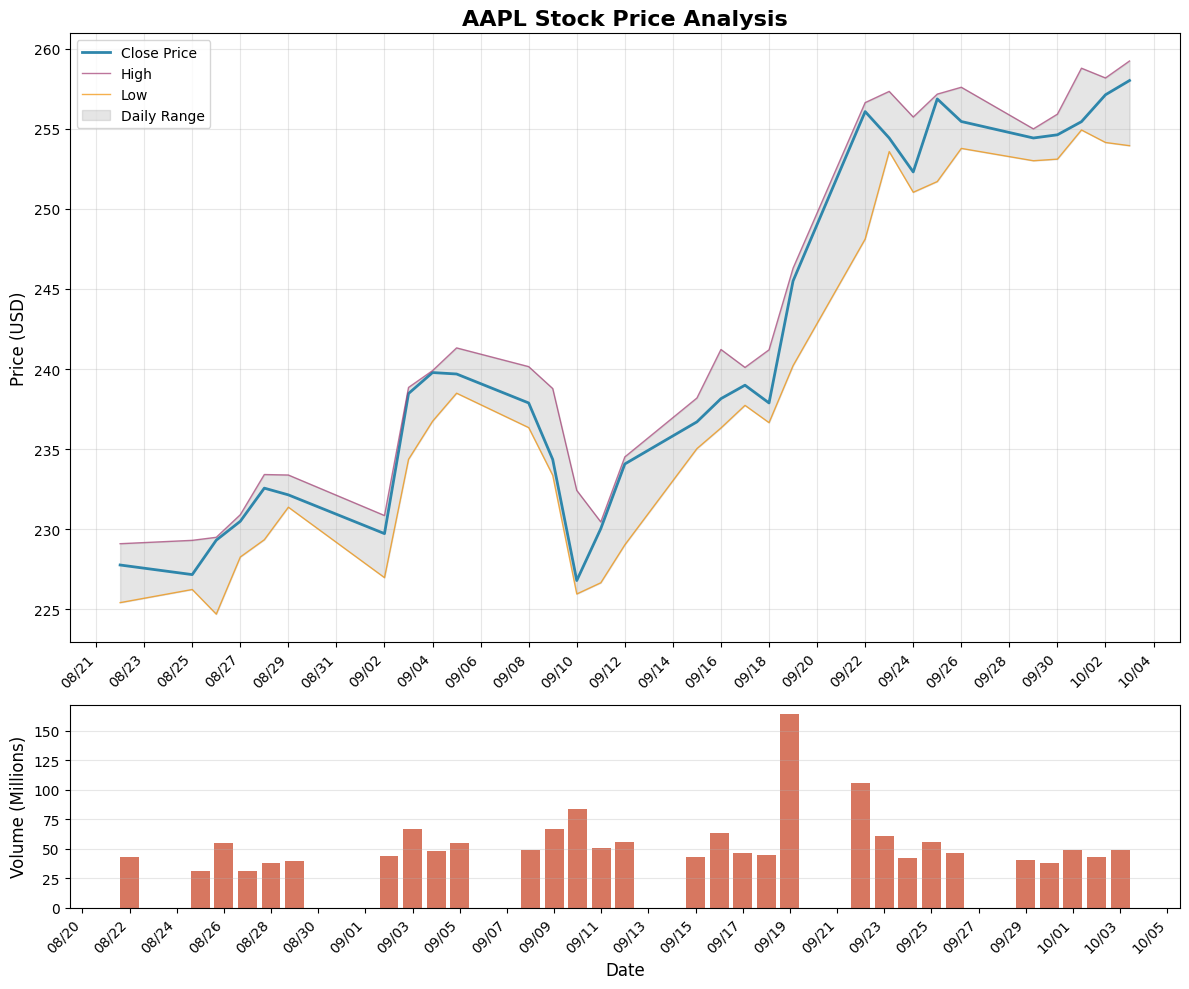


Key Visualization Statistics:
Price Range: $224.69 - $259.24
Average Volume: 54.8M shares
Price Volatility (std): $10.80
Average Daily Return: 0.44%
Return Volatility: 1.55%
   ⏱️  Completed in 0.79s

💾 Step 3: Saving to DuckDB...
✓ Successfully saved 30 rows to DuckDB table 'aapl_stocks'
✓ Database location: :memory:

Table Schema:
column_name   column_type null  key default extra
       Date          DATE  YES None    None  None
       Open DECIMAL(10,2)  YES None    None  None
       High DECIMAL(10,2)  YES None    None  None
        Low DECIMAL(10,2)  YES None    None  None
      Close DECIMAL(10,2)  YES None    None  None
     Volume        BIGINT  YES None    None  None
   ⏱️  Completed in 0.07s

🔍 Step 4: Verifying Data Storage...

Query Results - Top 10 rows:
      Date   Open   High    Low  Close    Volume  Daily_Change_Pct
2025-10-03 254.67 259.24 253.95 258.02  49107000              0.35
2025-10-02 256.58 258.18 254.15 257.13  42630200              0.66
2025-10-01 255.04 25

C:\Users\shouk\AppData\Local\Temp\ipykernel_25920\4224134104.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


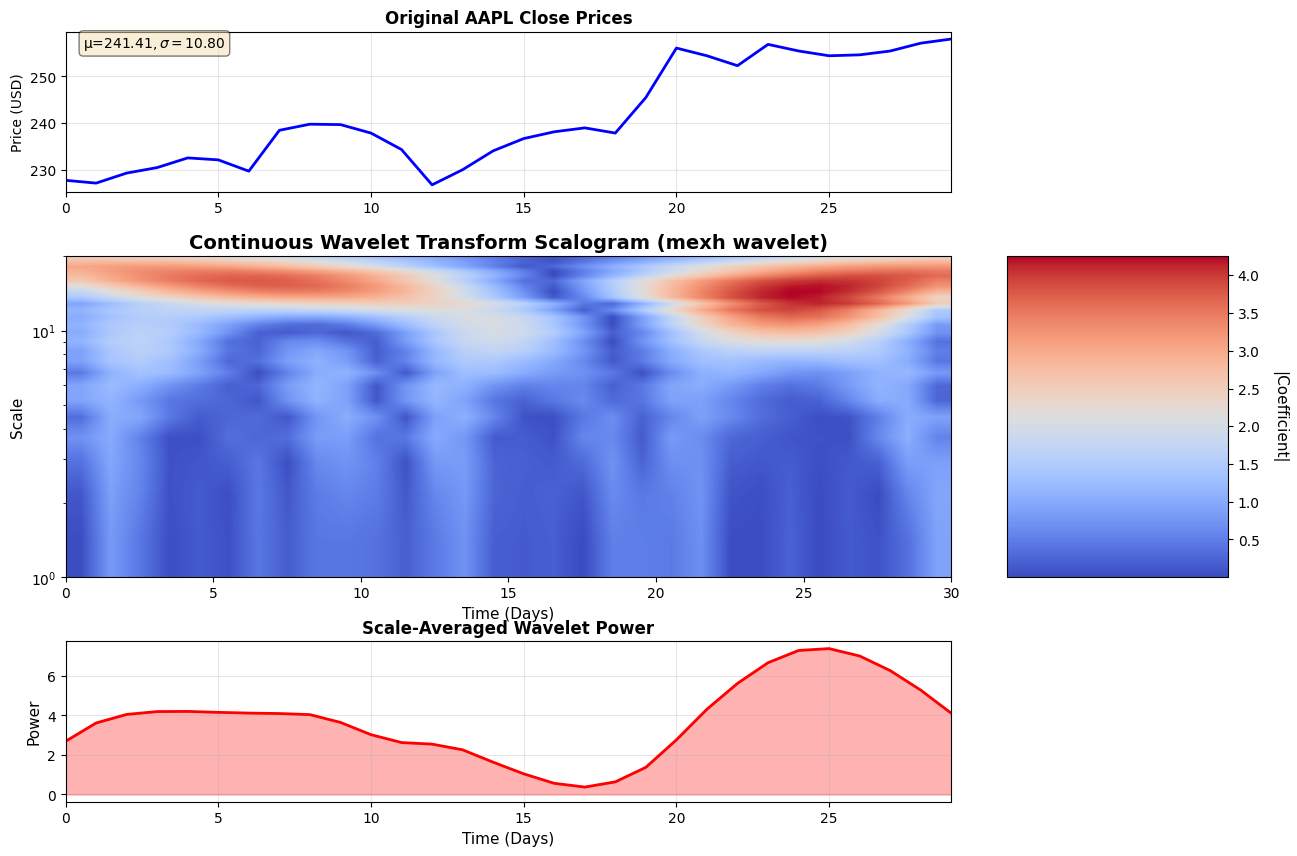


Wavelet Feature Analysis:

Scale Energy Distribution:
├─ Dominant scale index: 19
├─ Dominant scale value: 10.71
└─ Dominant scale energy: 283.33

Volatility Analysis:
├─ Mean power: 93.01
├─ Power std dev: 48.90
└─ Volatility threshold: 190.81

└─ No significant volatility spikes detected

Scale-wise Energy Distribution (5 representative scales):
------------------------------------------------------------
Scale  1.00: Energy =     4.66 ( 0.17%)
Scale  1.87: Energy =    14.17 ( 0.51%)
Scale  3.48: Energy =    56.99 ( 2.04%)
Scale  6.50: Energy =   186.01 ( 6.67%)
Scale 12.14: Energy =   259.05 ( 9.28%)

Frequency Band Analysis:
├─ High frequency energy (short-term): 302.68
├─ Low frequency energy (long-term): 2487.52
└─ Ratio (high/low): 0.12
   ⏱️  Completed in 0.32s

✅ Pipeline completed successfully!
Total execution time: 1.32 seconds
Data points processed: 30
Wavelet coefficients generated: 750
Memory usage (approx): 5.9 KB

🔒 Closing in-memory database connection...
✓ AAPL analy

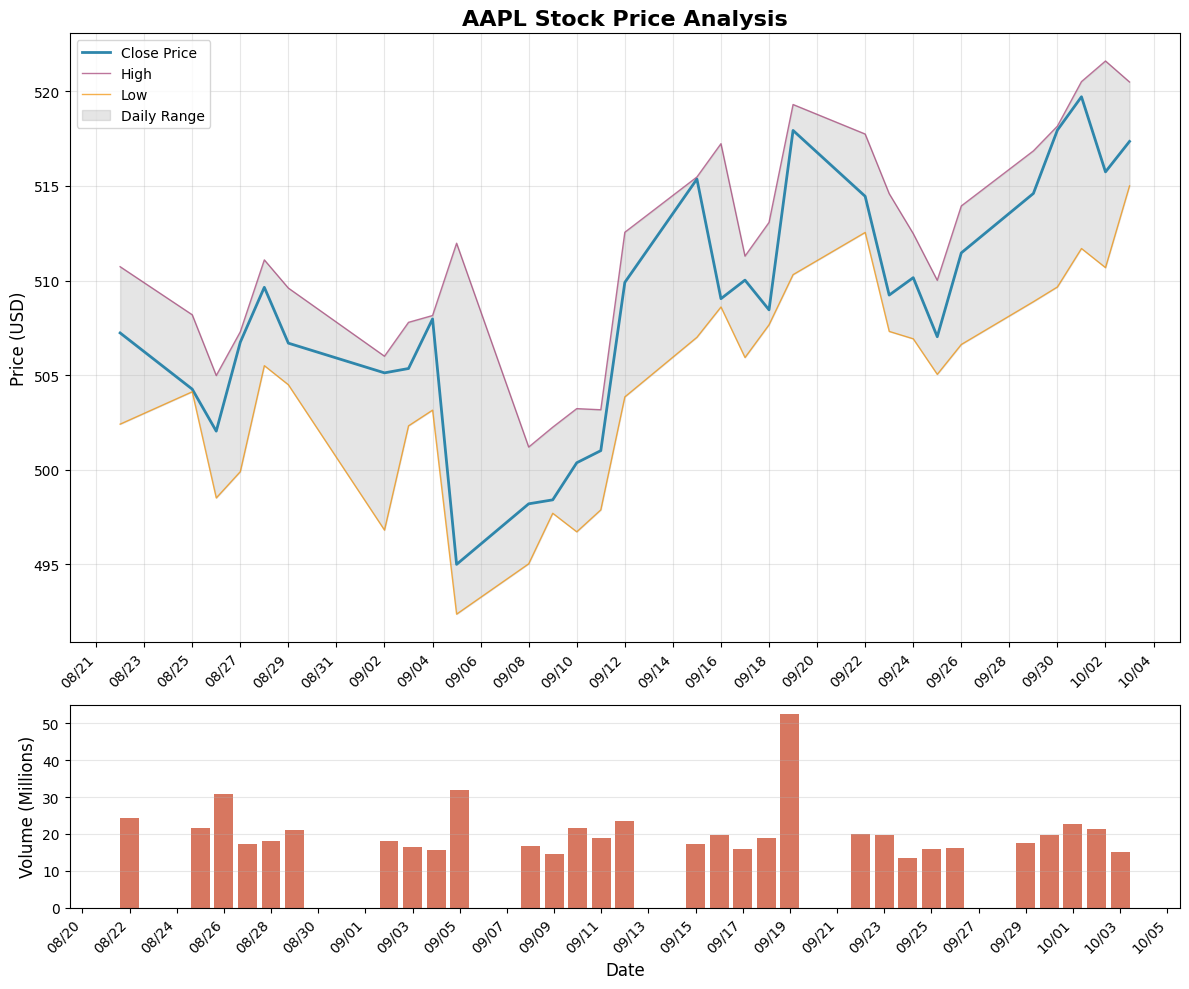


Key Visualization Statistics:
Price Range: $492.37 - $521.60
Average Volume: 20.5M shares
Price Volatility (std): $6.26
Average Daily Return: 0.07%
Return Volatility: 0.91%
   ⏱️  Completed in 0.79s

💾 Step 3: Saving to DuckDB...
✓ Successfully saved 30 rows to DuckDB table 'msft_stocks'
✓ Database location: :memory:

Table Schema:
column_name   column_type null  key default extra
       Date          DATE  YES None    None  None
       Open DECIMAL(10,2)  YES None    None  None
       High DECIMAL(10,2)  YES None    None  None
        Low DECIMAL(10,2)  YES None    None  None
      Close DECIMAL(10,2)  YES None    None  None
     Volume        BIGINT  YES None    None  None
   ⏱️  Completed in 0.02s

🔍 Step 4: Verifying Data Storage...

Query Results - Top 10 rows:
      Date   Open   High    Low  Close   Volume  Daily_Change_Pct
2025-10-03 517.10 520.49 515.00 517.35 15104200              0.31
2025-10-02 517.64 521.60 510.68 515.74 21222900             -0.76
2025-10-01 514.80 520.51

C:\Users\shouk\AppData\Local\Temp\ipykernel_25920\4224134104.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


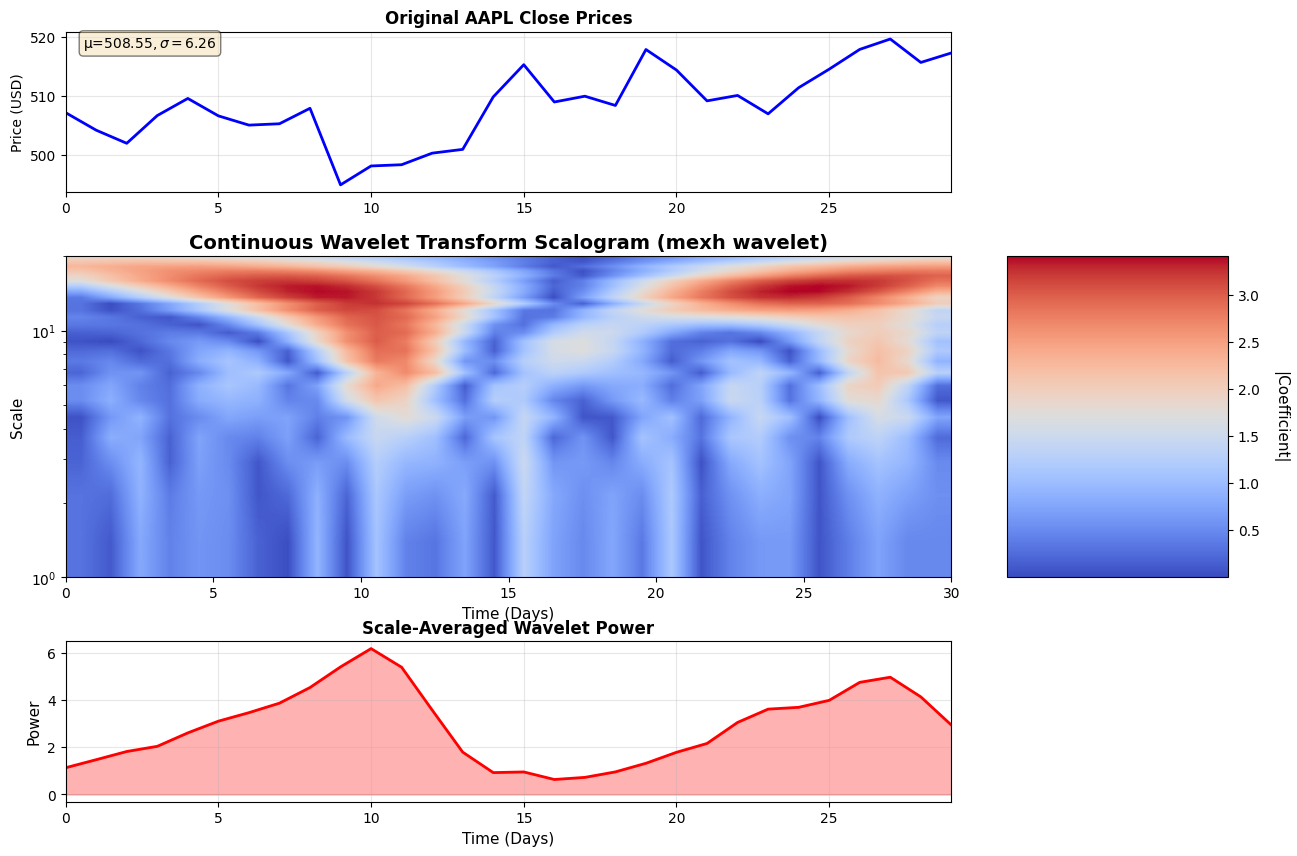


Wavelet Feature Analysis:

Scale Energy Distribution:
├─ Dominant scale index: 18
├─ Dominant scale value: 9.46
└─ Dominant scale energy: 198.87

Volatility Analysis:
├─ Mean power: 72.55
├─ Power std dev: 39.09
└─ Volatility threshold: 150.73

High Volatility Periods:
└─ Detected at days: [10]

Volatility Period Details:
  Day 10: 2025-09-08T00:00:00.000000000, Price: $498.20, Power: 154.63

Scale-wise Energy Distribution (5 representative scales):
------------------------------------------------------------
Scale  1.00: Energy =    11.15 ( 0.51%)
Scale  1.87: Energy =    33.65 ( 1.55%)
Scale  3.48: Energy =    58.27 ( 2.68%)
Scale  6.50: Energy =   145.66 ( 6.69%)
Scale 12.14: Energy =   167.12 ( 7.68%)

Frequency Band Analysis:
├─ High frequency energy (short-term): 441.61
├─ Low frequency energy (long-term): 1734.75
└─ Ratio (high/low): 0.25
   ⏱️  Completed in 0.47s

✅ Pipeline completed successfully!
Total execution time: 1.40 seconds
Data points processed: 30
Wavelet coefficien

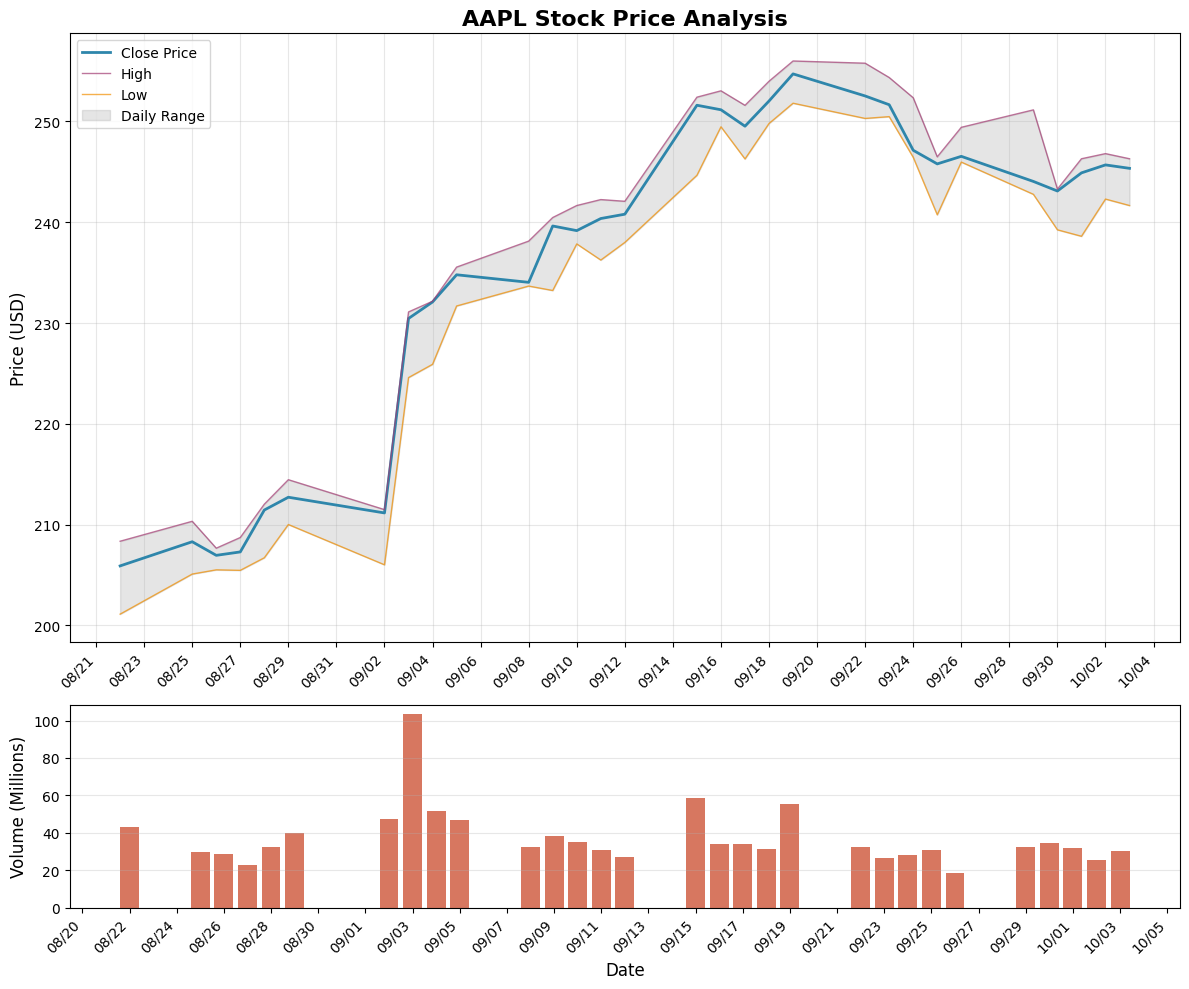


Key Visualization Statistics:
Price Range: $201.12 - $256.00
Average Volume: 37.1M shares
Price Volatility (std): $16.03
Average Daily Return: 0.63%
Return Volatility: 2.03%
   ⏱️  Completed in 0.76s

💾 Step 3: Saving to DuckDB...
✓ Successfully saved 30 rows to DuckDB table 'googl_stocks'
✓ Database location: :memory:

Table Schema:
column_name   column_type null  key default extra
       Date          DATE  YES None    None  None
       Open DECIMAL(10,2)  YES None    None  None
       High DECIMAL(10,2)  YES None    None  None
        Low DECIMAL(10,2)  YES None    None  None
      Close DECIMAL(10,2)  YES None    None  None
     Volume        BIGINT  YES None    None  None
   ⏱️  Completed in 0.02s

🔍 Step 4: Verifying Data Storage...

Query Results - Top 10 rows:
      Date   Open   High    Low  Close   Volume  Daily_Change_Pct
2025-10-03 244.49 246.30 241.66 245.35 30232900             -0.14
2025-10-02 245.15 246.81 242.30 245.69 25483300              0.32
2025-10-01 240.75 246.

C:\Users\shouk\AppData\Local\Temp\ipykernel_25920\4224134104.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


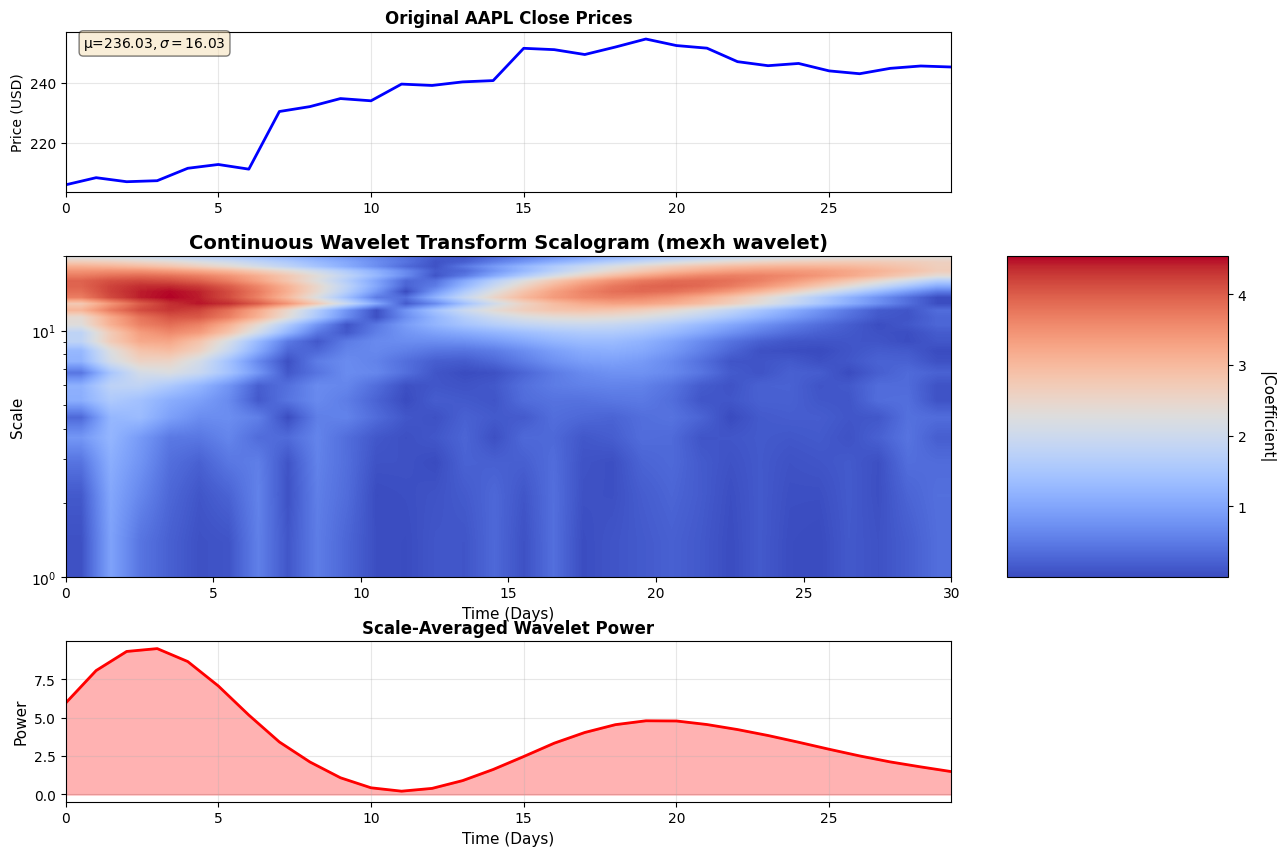


Wavelet Feature Analysis:

Scale Energy Distribution:
├─ Dominant scale index: 18
├─ Dominant scale value: 9.46
└─ Dominant scale energy: 288.02

Volatility Analysis:
├─ Mean power: 95.77
├─ Power std dev: 64.84
└─ Volatility threshold: 225.45

High Volatility Periods:
└─ Detected at days: [2, 3]

Volatility Period Details:
  Day 2: 2025-08-26T00:00:00.000000000, Price: $206.95, Power: 233.19
  Day 3: 2025-08-27T00:00:00.000000000, Price: $207.29, Power: 237.83

Scale-wise Energy Distribution (5 representative scales):
------------------------------------------------------------
Scale  1.00: Energy =     2.42 ( 0.08%)
Scale  1.87: Energy =    10.80 ( 0.38%)
Scale  3.48: Energy =    58.23 ( 2.03%)
Scale  6.50: Energy =   225.98 ( 7.87%)
Scale 12.14: Energy =   254.20 ( 8.85%)

Frequency Band Analysis:
├─ High frequency energy (short-term): 283.03
├─ Low frequency energy (long-term): 2589.98
└─ Ratio (high/low): 0.11
   ⏱️  Completed in 0.36s

✅ Pipeline completed successfully!
Total ex

In [12]:
# Example 2: Comparative analysis (commented out)
print("\n\nExample 2: Comparative Analysis")
comparative_results = run_comparative_analysis(["AAPL", "MSFT", "GOOGL"], "30d")



Example 3: Persistent Storage
🚀 Starting Stock Analysis Pipeline
Target: AAPL
Period: 60d
Database: ./data/stock_analysis.duckdb
Timestamp: 2025-10-05 15:41:26

📊 Step 1: Loading Stock Data...
Fetching 60d of data for AAPL...
Successfully loaded 60 days of data for AAPL

Date range: 2025-07-11 00:00:00 to 2025-10-03 00:00:00

Stock Data Preview:
Price       Date       Close        High         Low        Open    Volume
0     2025-07-11  210.920624  211.889525  209.622094  210.331296  39765800
1     2025-07-14  208.383499  210.670912  207.304722  209.692012  38840100
2     2025-07-15  208.872955  211.649803  208.683168  208.982831  42296300
3     2025-07-16  209.921768  212.159219  208.403487  210.061609  47490500
4     2025-07-17  209.781921  211.559902  209.352401  210.331301  48068100

Basic Statistics:
Average Close Price: $229.10
Price Range: $201.27 - $259.24
Average Daily Volume: 55.6M shares
   ⏱️  Completed in 0.18s

📈 Step 2: Creating Visualizations...


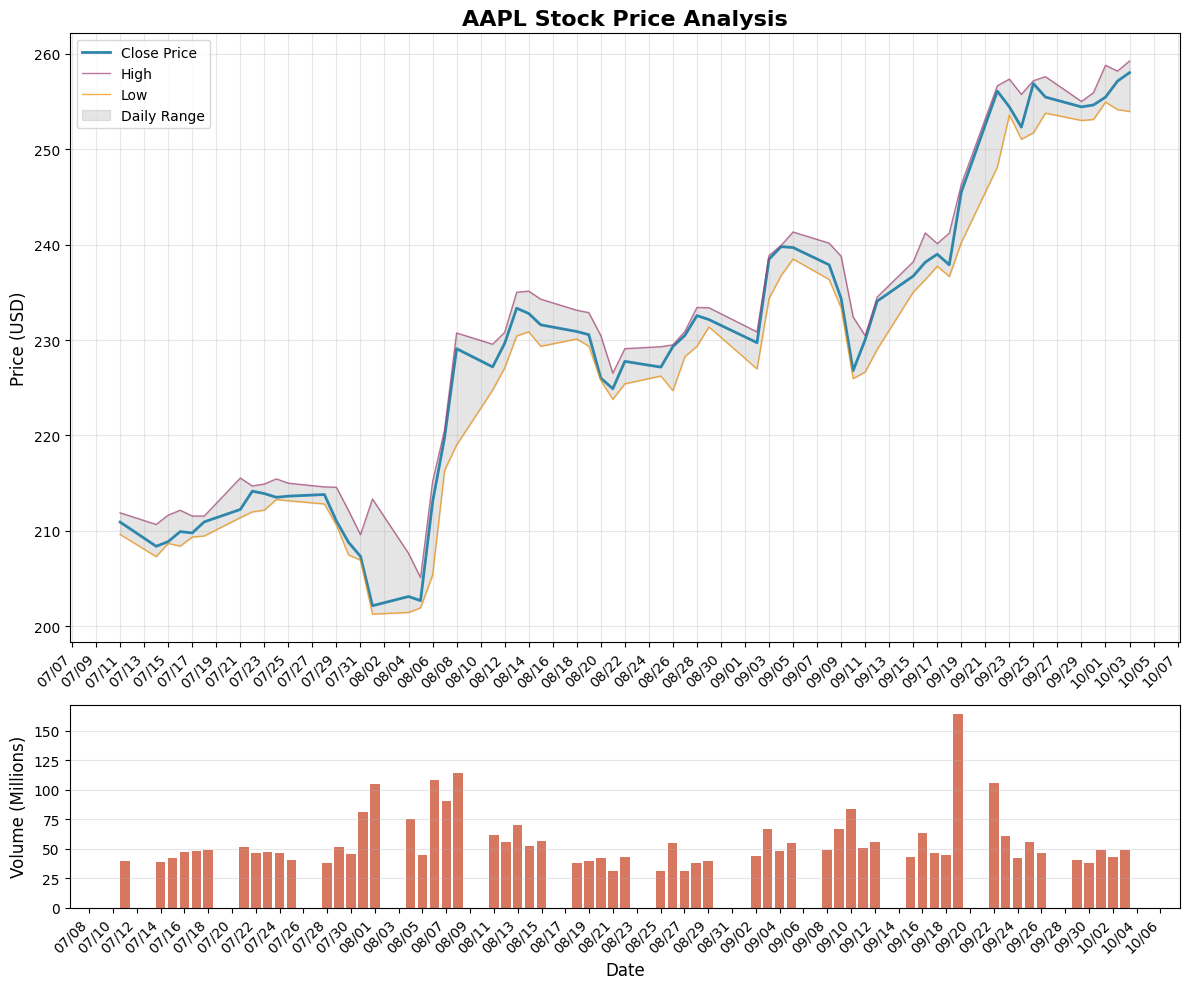


Key Visualization Statistics:
Price Range: $201.27 - $259.24
Average Volume: 55.6M shares
Price Volatility (std): $16.06
Average Daily Return: 0.35%
Return Volatility: 1.57%
   ⏱️  Completed in 1.17s

💾 Step 3: Saving to DuckDB...
✓ Successfully saved 60 rows to DuckDB table 'aapl_stocks'
✓ Database location: ./data/stock_analysis.duckdb

Table Schema:
column_name   column_type null  key default extra
       Date          DATE  YES None    None  None
       Open DECIMAL(10,2)  YES None    None  None
       High DECIMAL(10,2)  YES None    None  None
        Low DECIMAL(10,2)  YES None    None  None
      Close DECIMAL(10,2)  YES None    None  None
     Volume        BIGINT  YES None    None  None
   ⏱️  Completed in 0.65s

🔍 Step 4: Verifying Data Storage...

Query Results - Top 10 rows:
      Date   Open   High    Low  Close    Volume  Daily_Change_Pct
2025-10-03 254.67 259.24 253.95 258.02  49107000              0.35
2025-10-02 256.58 258.18 254.15 257.13  42630200              0.66


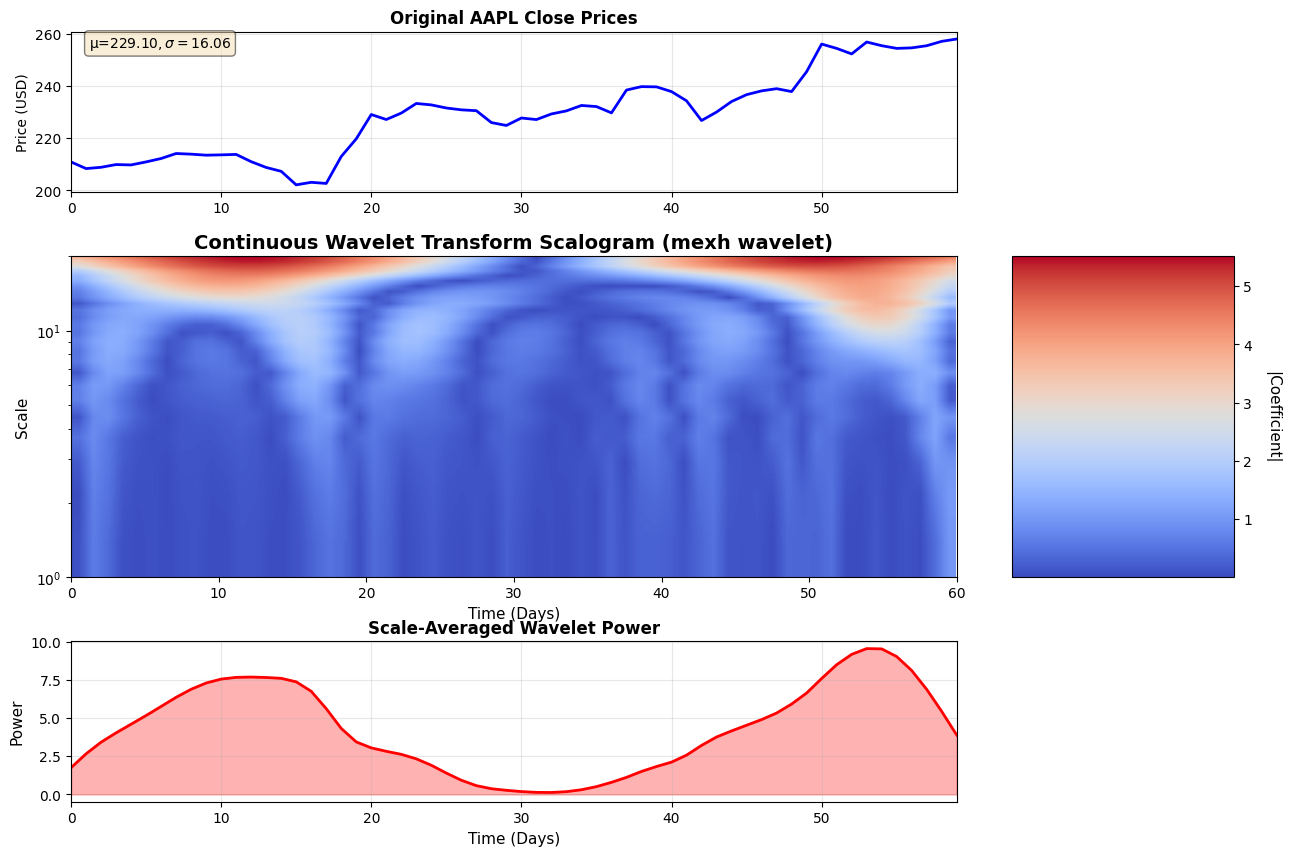


Wavelet Feature Analysis:

Scale Energy Distribution:
├─ Dominant scale index: 24
├─ Dominant scale value: 20.00
└─ Dominant scale energy: 1107.50

Volatility Analysis:
├─ Mean power: 107.28
├─ Power std dev: 71.76
└─ Volatility threshold: 250.80

└─ No significant volatility spikes detected

Scale-wise Energy Distribution (5 representative scales):
------------------------------------------------------------
Scale  1.00: Energy =     4.02 ( 0.06%)
Scale  1.87: Energy =    17.18 ( 0.27%)
Scale  3.48: Energy =    71.30 ( 1.11%)
Scale  6.50: Energy =   179.87 ( 2.79%)
Scale 12.14: Energy =   543.12 ( 8.44%)

Frequency Band Analysis:
├─ High frequency energy (short-term): 368.42
├─ Low frequency energy (long-term): 6068.55
└─ Ratio (high/low): 0.06
   ⏱️  Completed in 0.34s

✅ Pipeline completed successfully!
Total execution time: 2.35 seconds
Data points processed: 60
Wavelet coefficients generated: 1,500
Memory usage (approx): 11.7 KB


In [15]:
# Example 3: Persistent database storage (commented out)
print("\n\nExample 3: Persistent Storage")
result = main("AAPL", "60d", db_path="./data/stock_analysis.duckdb")

## 3.10 Advanced Topic: Wavelet-Based Forecasting
### 3.10.2 Implementation


🔮 WAVELET-BASED STOCK PRICE FORECASTING
Ticker: AAPL
Forecast Horizon: 1 day(s)
Model: RF

📊 Step 1: Loading stock data...
Fetching 90d of data for AAPL...
Successfully loaded 90 days of data for AAPL

Date range: 2025-06-02 00:00:00 to 2025-10-08 00:00:00

Stock Data Preview:
Price       Date       Close        High         Low        Open    Volume
0     2025-06-02  201.471344  201.900864  199.893133  200.052956  35423300
1     2025-06-03  203.039566  203.538999  200.732187  201.121744  46381600
2     2025-06-04  202.590088  206.006209  201.870903  202.679982  43604000
3     2025-06-05  200.402573  204.517897  199.923106  203.269314  55126100
4     2025-06-06  203.688828  205.466808  201.820952  202.769872  46607700

Basic Statistics:
Average Close Price: $222.24
Price Range: $194.85 - $259.24
Average Daily Volume: 54.6M shares

🌊¡ Step 2: Performing wavelet decomposition...

Wavelet Analysis Summary:
├─ Wavelet type: mexh
├─ Number of scales: 20
├─ Data points: 90
├─ Coefficient mat

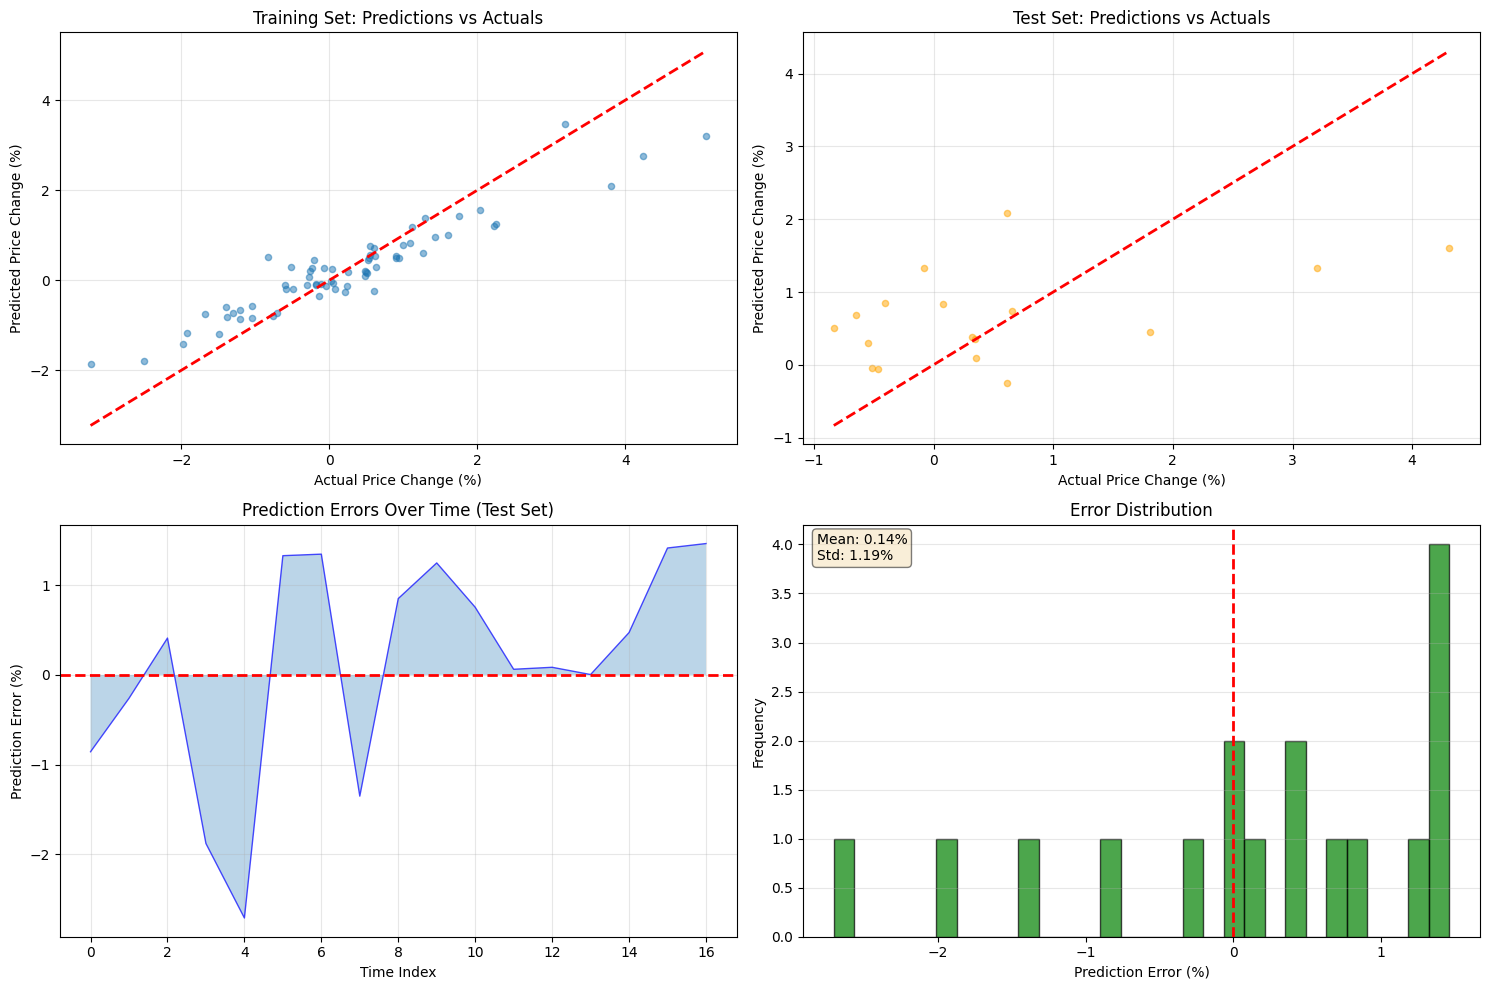


🔍 Top 10 Most Important Features:
  1. Feature 3: 0.1120
  2. Feature 39: 0.0498
  3. Feature 28: 0.0491
  4. Feature 7: 0.0428
  5. Feature 29: 0.0401
  6. Feature 24: 0.0339
  7. Feature 21: 0.0310
  8. Feature 25: 0.0287
  9. Feature 33: 0.0253
  10. Feature 22: 0.0208

🔮 NEXT-DAY FORECAST
🔮 WAVELET-BASED STOCK PRICE FORECASTING
Ticker: AAPL
Forecast Horizon: 1 day(s)
Model: RF

📊 Step 1: Loading stock data...
Fetching 90d of data for AAPL...
Successfully loaded 90 days of data for AAPL

Date range: 2025-06-02 00:00:00 to 2025-10-08 00:00:00

Stock Data Preview:
Price       Date       Close        High         Low        Open    Volume
0     2025-06-02  201.471344  201.900864  199.893133  200.052956  35423300
1     2025-06-03  203.039566  203.538999  200.732187  201.121744  46381600
2     2025-06-04  202.590088  206.006209  201.870903  202.679982  43604000
3     2025-06-05  200.402573  204.517897  199.923106  203.269314  55126100
4     2025-06-06  203.688828  205.466808  201.820952

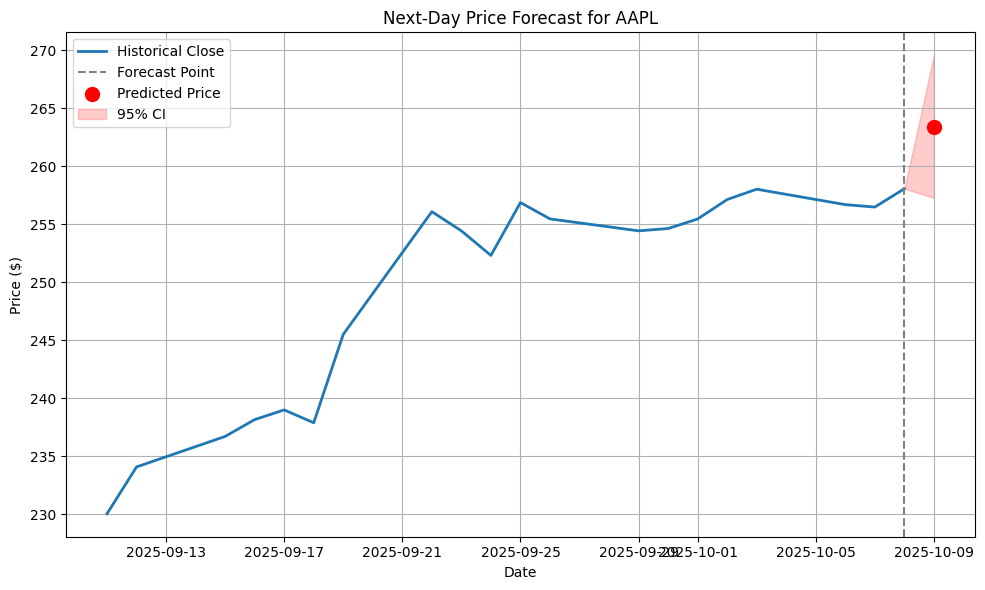

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def visualize_next_day_forecast(stock_data, current_price, predicted_price, uncertainty, ticker):
    """
    Visualize the next-day forecast with historical prices and confidence interval.
    
    Parameters:
    -----------
    stock_data : pd.DataFrame
        Historical stock data with Date and Close columns
    current_price : float
        Current closing price
    predicted_price : float
        Predicted price for the next day
    uncertainty : float
        Prediction uncertainty (standard deviation of test errors, in percentage)
    ticker : str
        Stock symbol
    """
    plt.figure(figsize=(10, 6))
    # Plot last 20 days of historical data for context
    plot_data = stock_data.tail(20)
    plt.plot(plot_data['Date'], plot_data['Close'], label='Historical Close', color='#1f77b4', linewidth=2)
    
    # Forecast date (next trading day)
    forecast_date = stock_data['Date'].iloc[-1] + pd.Timedelta(days=1)
    plt.axvline(stock_data['Date'].iloc[-1], color='gray', linestyle='--', label='Forecast Point')
    
    # Predicted price
    plt.scatter([forecast_date], [predicted_price], color='red', s=100, label='Predicted Price', zorder=5)
    
    # 95% Confidence Interval (±2 standard deviations, converted to price)
    ci_lower = current_price * (1 + (predicted_price / current_price - 1 - 2 * uncertainty / 100))
    ci_upper = current_price * (1 + (predicted_price / current_price - 1 + 2 * uncertainty / 100))
    plt.fill_between([stock_data['Date'].iloc[-1], forecast_date],
                     [current_price, ci_lower],
                     [current_price, ci_upper],
                     color='red', alpha=0.2, label='95% CI')
    
    plt.xlabel('Date')
    plt.ylabel('Price ($)')
    plt.title(f'Next-Day Price Forecast for {ticker}')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f'./output/next_day_forecast_{ticker}.png', dpi=300)
    plt.show()

def run_forecasting_pipeline(ticker="AAPL", period="60d", forecast_horizon=1, 
                            window_size=5, model_type='rf', plot=True):
    """
    Complete forecasting pipeline integrating wavelet analysis with ML.
    
    Parameters:
    -----------
    ticker : str
        Stock symbol
    period : str
        Historical data period
    forecast_horizon : int
        Days ahead to forecast
    window_size : int
        Historical window for features
    model_type : str
        'rf' or 'gb' for model type
    plot : bool
        Whether to generate evaluation visualizations (default: True)
        
    Returns:
    --------
    dict
        Complete results including model, predictions, and metrics
    """
    print("="*70)
    print("🔮 WAVELET-BASED STOCK PRICE FORECASTING")
    print("="*70)
    print(f"Ticker: {ticker}")
    print(f"Forecast Horizon: {forecast_horizon} day(s)")
    print(f"Model: {model_type.upper()}")
    print("="*70)
    
    # Step 1: Load data
    print("\n📊 Step 1: Loading stock data...")
    stock_data = load_stock_data(ticker, period)
    if stock_data is None or len(stock_data) < 30:
        print("❌ Insufficient data for forecasting")
        return None
    
    # Step 2: Wavelet decomposition
    print("\n🌊¡ Step 2: Performing wavelet decomposition...")
    scales = np.logspace(0, np.log10(15), 20)
    coefficients, frequencies, scales = apply_wavelet_transform(
        stock_data, scales=scales, plot_scalogram=False
    )
    
    # Step 3: Feature extraction
    print("\n🔧 Step 3: Extracting wavelet features...")
    features = extract_wavelet_features(coefficients, scales, window_size)
    print(f"   Feature matrix shape: {features.shape}")
    print(f"   Number of features per sample: {features.shape[1]}")
    
    # Step 4: Create targets
    print("\n🎯 Step 4: Creating target variables...")
    price_targets, direction_targets, target_dates = create_targets(
        stock_data, window_size, forecast_horizon
    )
    
    # Align features and targets
    min_len = min(len(features), len(price_targets))
    features = features[:min_len]
    price_targets = price_targets[:min_len]
    direction_targets = direction_targets[:min_len]
    target_dates = target_dates[:min_len]
    
    print(f"   Number of training samples: {len(features)}")
    print(f"   Target price changes range: [{price_targets.min():.2f}%, {price_targets.max():.2f}%]")
    
    # Step 5: Train model
    print(f"\n🤖 Step 5: Training {model_type.upper()} model...")
    model, scaler, (train_pred, test_pred), (y_train, y_test), (train_metrics, test_metrics) = \
        train_forecasting_model(features, price_targets, test_size=0.2, model_type=model_type)
    
    # Step 6: Evaluate
    print("\n📈 Step 6: Model Evaluation")
    print("="*70)
    print("\nTraining Metrics:")
    print(f"  MSE:  {train_metrics['mse']:.4f}")
    print(f"  MAE:  {train_metrics['mae']:.4f}")
    print(f"  RÂ²:   {train_metrics['r2']:.4f}")
    
    print("\nTest Metrics:")
    print(f"  MSE:  {test_metrics['mse']:.4f}")
    print(f"  MAE:  {test_metrics['mae']:.4f}")
    print(f"  RÂ²:   {test_metrics['r2']:.4f}")
    
    # Calculate directional accuracy
    test_direction_pred = (test_pred > 0).astype(int)
    split_idx = int(len(direction_targets) * 0.8)
    test_direction_actual = direction_targets[split_idx:][:len(test_pred)]
    
    directional_accuracy = np.mean(test_direction_pred == test_direction_actual) * 100
    print(f"\nDirectional Accuracy: {directional_accuracy:.2f}%")
    
    # Step 7: Visualize (only if plot=True)
    if plot:
        print("\n📊 Step 7: Generating visualizations...")
        visualize_predictions(y_train, y_test, train_pred, test_pred, 
                             target_dates[split_idx:][:len(test_pred)])
    
    # Step 8: Feature importance (for tree-based models)
    if hasattr(model, 'feature_importances_'):
        print("\n🔍 Top 10 Most Important Features:")
        importances = model.feature_importances_
        indices = np.argsort(importances)[::-1][:10]
        for i, idx in enumerate(indices, 1):
            print(f"  {i}. Feature {idx}: {importances[idx]:.4f}")
    
    # Return results
    return {
        'model': model,
        'scaler': scaler,
        'features': features,
        'targets': price_targets,
        'predictions': (train_pred, test_pred),
        'actuals': (y_train, y_test),
        'metrics': (train_metrics, test_metrics),
        'directional_accuracy': directional_accuracy,
        'stock_data': stock_data,
        'coefficients': coefficients
    }

def forecast_next_day(ticker="AAPL", period="60d", window_size=5):
    """
    Make a forecast for the next trading day.
    
    Parameters:
    -----------
    ticker : str
        Stock symbol
    period : str
        Historical period for training
    window_size : int
        Historical window size
        
    Returns:
    --------
    dict
        Forecast results with confidence metrics
    """
    print("\n" + "="*70)
    print("🔮 NEXT-DAY FORECAST")
    print("="*70)
    
    # Train model on all available data without plotting
    result = run_forecasting_pipeline(ticker, period, forecast_horizon=1, 
                                     window_size=window_size, model_type='rf', plot=False)
    
    if result is None:
        return None
    
    # Get most recent features
    recent_features = result['features'][-1:, :]
    recent_features_scaled = result['scaler'].transform(recent_features)
    
    # Make prediction
    prediction = result['model'].predict(recent_features_scaled)[0]
    
    # Get current price
    current_price = result['stock_data']['Close'].iloc[-1]
    predicted_price = current_price * (1 + prediction / 100)
    
    # Calculate prediction uncertainty using historical errors
    test_errors = result['predictions'][1] - result['actuals'][1]
    prediction_std = np.std(test_errors)
    
    print(f"\nCurrent Price: ${current_price:.2f}")
    print(f"Predicted Change: {prediction:+.2f}%")
    print(f"Predicted Price: ${predicted_price:.2f}")
    print(f"Prediction Uncertainty (±1σ): {prediction_std:.2f}%")
    print(f"95% Confidence Interval: ${current_price * (1 + (prediction - 2*prediction_std)/100):.2f} - "
          f"${current_price * (1 + (prediction + 2*prediction_std)/100):.2f}")
    print(f"Direction: {'📈 UP' if prediction > 0 else '📉 DOWN'}")
    
    # Generate forecast visualization
    visualize_next_day_forecast(result['stock_data'], current_price, predicted_price, prediction_std, ticker)
    
    return {
        'current_price': current_price,
        'predicted_change_pct': prediction,
        'predicted_price': predicted_price,
        'uncertainty': prediction_std,
        'direction': 'UP' if prediction > 0 else 'DOWN',
        'model_r2': result['metrics'][1]['r2'],
        'directional_accuracy': result['directional_accuracy']
    }

# Example usage
if __name__ == "__main__":
    # Example: Run forecasting pipeline with visualizations
    result = run_forecasting_pipeline("AAPL", period="90d", forecast_horizon=1, 
                                     window_size=5, model_type='rf', plot=True)
    
    # Example: Forecast next day with dedicated visualization
    if result:
        next_day_forecast = forecast_next_day("AAPL", period="90d", window_size=5)